# Fusing Photos, Text and Listing Details to Predict Airbnb Price Levels

**Project Part 2: implementation, evaluation and comparison**

## Overview

**Problem.** It is hard for new hosts to choose a fair price for one night, and it is hard for guests to know if a listing is good value. The price of a listing depends on different types of information. The listing details show how big the place is, the photo shows its condition and style, and the description tells us about the facilities and the location. Multimodal learning works best when each type of information gives something new that the others do not have (Liang et al., 2024), so I use all three together.

**Task.** Classify each Melbourne Airbnb listing as **budget**, **mid-range** or **premium** (three equal price groups).

**Modalities.**
* **Image:** the main listing photo, turned into numbers with EfficientNet-B0 (Week 4 practical)
* **Text:** the listing title and host description, turned into numbers with BERT mean pooling (Week 4 practical)
* **Tabular:** room type, capacity, bedrooms, bathrooms, amenities, reviews and area

**Approaches compared.** I compare three single-modality baselines with early fusion, late fusion and attention-based fusion (Weeks 4 and 5 lectures and practicals), as planned in the proposal. After the first results showed that the tabular data dominated, I added improvements from the course: CLIP image features (Week 8), stacking and gated fusion (Week 4), auxiliary losses (Weeks 5 and 7) and a fusion ensemble (Weeks 4 and 5). The final model is chosen on the validation set.

**Success criterion (from the proposal).** The best fusion model beats the best single-modality model on test macro F1, by more than the variation between random seeds (Week 7 practical).

**Data.** Inside Airbnb, Melbourne snapshot of 16 September 2026, licence CC BY 4.0 (https://insideairbnb.com/get-the-data/).



## Changes from the proposal

| Change | Reason |
|---|---|
| XGBoost is the classifier for the baselines, early fusion and late fusion | The proposal did not name a classifier. I use the same tree model as in Assignment 2, so early and late fusion differ only in **when** the modalities are combined |
| The listing title is joined to the description | The title often names the property type and view, which is useful price information |
| More tabular features (amenity flags, minimum nights, availability) | Richer listing details, all from the same file |
| Listings that share a **photo** are also kept in the same split | The proposal grouped copied descriptions; shared photos cause the same leakage |
| CLIP image features added as a reference | The brief suggests comparing with state-of-the-art models (Week 8) |
| BERT [CLS] compared with mean pooling, CLIP compared with EfficientNet | To justify the choice of feature extractors (the brief allows BERT mean-pooled or [CLS]) |
| Extra evaluation from Weeks 7 and 8: AUC, calibration, seeds, shuffle and noise tests, CKA, fairness metrics, unseen areas | To evaluate the models thoroughly, as taught in Weeks 7 and 8 |
| Improvements after the first results (Section 9.4): CLIP image features, stacking, gated fusion, auxiliary losses, smaller learning rate, fusion ensemble | The first results showed that the tabular data dominated and fusion gained very little; these course methods address that. The final model is chosen on the validation set |

## 1. Setup and settings

I keep all the settings in one place (the `CFG` dictionary), so it is easy to see and change them. The settings are also saved together with the results.

In [1]:
# Libraries that are not always in Colab
# !pip install -q xgboost transformers scikit-image

import io
import re
import copy
import html
import json
import time
import random
import warnings
import concurrent.futures as cf
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import xgboost as xgb
from transformers import AutoTokenizer, AutoModel
from skimage.filters import laplace
from skimage.measure import shannon_entropy
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
    confusion_matrix,
    log_loss,
)

# I hide only the "this will change in a future version" messages, because
# they do not change any result
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Settings
CFG = {
    # Data
    "snapshot_url": (
        "https://data.insideairbnb.com/australia/vic/melbourne/2026-09-16/"
        "data/listings.csv.gz"
    ),
    "snapshot_date": "2026-09-16",
    "price_cap_quantile": 0.99,  # remove the top 1% of prices (proposal)
    "quick_run": None,  # None = all listings; a number = small test run
    # Split: 20 grouped folds; 3 folds test, 3 folds validation (70/15/15)
    "n_folds": 20,
    "seed": 42,
    "n_seeds": 3,  # every model is trained with 3 seeds (Week 7 practical)
    # Images
    "img_workers": 32,  # photos downloaded at the same time
    "img_width": 480,  # small photos are enough for a 224 x 224 network
    "img_chunk": 1024,  # photos per saved piece
    "img_batch": 128,
    "clip_name": "openai/clip-vit-base-patch32",
    # Text
    "bert_name": "bert-base-uncased",
    "bert_max_len": 256,
    "bert_batch": 64,
    # Trees: settings searched on the validation set
    "xgb_grid": {"n_pca": [32, 64], "max_depth": [4, 6],
                 "learning_rate": [0.05, 0.1]},
    # Attention fusion: settings searched on the validation set
    "att_grid": {"hidden_dim": [128, 256], "dropout": [0.2, 0.4]},
    "att_epochs": 60,  # as in the Week 6 and 7 practicals
    "att_batch": 256,
    "att_lr": 1e-3,  # as in the Week 6 and 7 practicals
    "att_weight_decay": 1e-4,  # as in the Week 6 and 7 practicals
    "att_heads": 4,
    "att_modality_dropout": 0.1,
    # Improvements (Section 9.4), chosen on the validation set
    "imp_lr": [1e-3, 3e-4],
    "imp_aux_weight": [0.0, 0.3],
    # Robustness and generalisation checks
    "noise_levels": [0.5, 1.0],
    "n_area_holdouts": 3,
    "area_holdout_share": 0.2,
}
QUICK_RUN = CFG["quick_run"]
# smallest number of test listings for a group to be reported in the bias
# checks (smaller groups give unreliable numbers)
MIN_GROUP = 10 if QUICK_RUN else 30
SEEDS = [CFG["seed"] + s for s in range(CFG["n_seeds"])]

# I fix the random seed so I get the same results every time I run it
SEED = CFG["seed"]
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# I save everything in Google Drive, so it is not lost if Colab disconnects
try:
    from google.colab import drive

    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/airbnb_fusion")
except Exception:
    OUT = Path("airbnb_fusion_outputs")
if QUICK_RUN:
    OUT = OUT / f"quick_{QUICK_RUN}"
FEAT_DIR, FIG_DIR, TAB_DIR = OUT / "features", OUT / "figures", OUT / "tables"
for d in (FEAT_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)
with open(OUT / "config.json", "w") as f:
    json.dump(CFG, f, indent=1)
print("Results are saved in:", OUT)

CLASSES = ["budget", "mid-range", "premium"]
# I give each class its own colour and use it in every plot
CLASS_COLOURS = ["#4c9f70", "#e9c46a", "#e76f51"]
# Greys for the single-modality baselines and colours for the fusion models
MODEL_COLOURS = {
    "Image only": "#c7c7c7",
    "Text only": "#9e9e9e",
    "Tabular only": "#6e6e6e",
    "Early fusion": "#457b9d",
    "Late fusion": "#2a9d8f",
    "Attention fusion": "#e76f51",
}
MODS = ["image", "text", "tabular"]


def colour(model):
    """Colour of a model in the plots (purple for the improved models)."""
    return MODEL_COLOURS.get(model, "#8d5a97")


def save_fig(fig, name):
    """Save a figure for the report (PNG, 200 dpi) and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


def save_table(table, name):
    """Save a results table as CSV for the report and show it."""
    table.to_csv(TAB_DIR / f"{name}.csv")
    display(table)

Device: cuda
Mounted at /content/drive
Results are saved in: /content/drive/MyDrive/airbnb_fusion


## 2. Load the data and remove personal data

The brief and my proposal say that no sensitive personal data may be used. Before any analysis I remove:
* every column about the host as a person (`host_*`: name, photo, profile text, location, response behaviour),
* the exact latitude and longitude, because Szanto and Mehta (2018) re-identified about 40% of tested Airbnb hosts from public listing data and location.

Only the area name (`neighbourhood_cleansed`) is kept as location.

In [2]:
raw = pd.read_csv(CFG["snapshot_url"], compression="gzip", low_memory=False)
print(f"Snapshot {CFG['snapshot_date']}: {len(raw):,} listings, "
      f"{raw.shape[1]} columns")

# Columns about the host as a person, the exact location and other columns
# I do not need
PERSONAL = [c for c in raw.columns if c.startswith("host_")] + [
    "latitude", "longitude", "listing_url", "scrape_id", "source",
    "calendar_updated", "neighborhood_overview", "neighbourhood",
]
KEEP = [
    "id", "name", "description", "picture_url", "price", "room_type",
    "property_type", "accommodates", "bedrooms", "beds", "bathrooms_text",
    "amenities", "minimum_nights", "availability_365", "number_of_reviews",
    "review_scores_rating", "instant_bookable", "neighbourhood_cleansed",
]
dropped = [c for c in PERSONAL if c in raw.columns]
df = raw[[c for c in KEEP if c in raw.columns]].copy()
print(f"Removed {len(dropped)} personal or unused columns, for example "
      f"{dropped[:4]}. Kept {df.shape[1]} columns.")
del raw

Snapshot 2026-09-16: 25,715 listings, 90 columns
Removed 28 personal or unused columns, for example ['host_id', 'host_url', 'host_profile_id', 'host_profile_url']. Kept 18 columns.


## 3. Target: three price levels

Price is stored as text like `$1,234.00`. As in my initial analysis:
* listings without a price are removed (they are mostly inactive),
* prices above the 99th percentile are removed as likely errors or special events,
* the remaining prices are split into three equal groups (tertiles), so the classes are balanced by design and accuracy is easy to read (random guessing = 33.3%).

Table 1. Data summary


,value
listings in snapshot,25715.0
no price (removed),6711.0
above 99th percentile (removed),191.0
price cap ($ per night),1553.0
listings used,18813.0
budget upper edge ($),203.0
mid-range upper edge ($),325.0


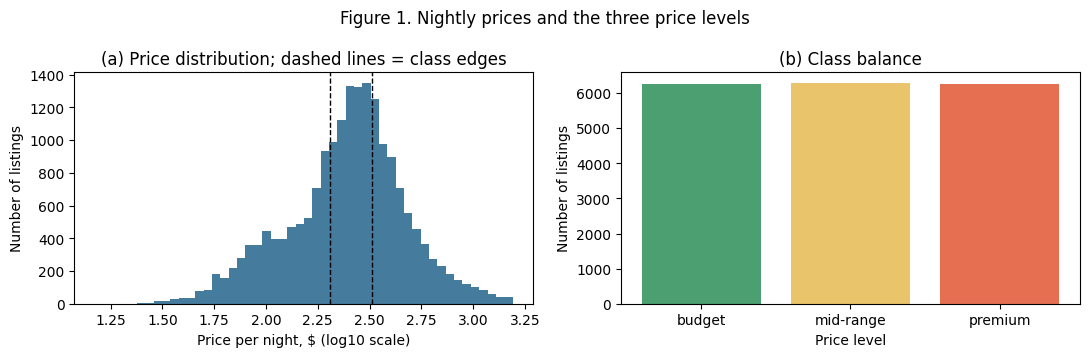

In [3]:
df["price_num"] = pd.to_numeric(
    df["price"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce",
)
n_all = len(df)
no_price = df["price_num"].isna() | (df["price_num"] <= 0)
df = df[~no_price].copy()
cap = df["price_num"].quantile(CFG["price_cap_quantile"])
n_out = int((df["price_num"] > cap).sum())
df = df[df["price_num"] <= cap].copy()
# Three equal groups: 0 = budget, 1 = mid-range, 2 = premium
df["y"], edges = pd.qcut(df["price_num"], 3, labels=False, retbins=True)
df["y"] = df["y"].astype(int)
df["price_level"] = df["y"].map(dict(enumerate(CLASSES)))

# For a quick test run I keep a small sample with the same class balance
if QUICK_RUN:
    df = pd.concat([
        g.sample(min(len(g), QUICK_RUN // 3), random_state=SEED)
        for _, g in df.groupby("y")
    ])
df = df.reset_index(drop=True)

data_summary = pd.Series({
    "listings in snapshot": n_all,
    "no price (removed)": int(no_price.sum()),
    "above 99th percentile (removed)": n_out,
    "price cap ($ per night)": round(cap, 0),
    "listings used": len(df),
    "budget upper edge ($)": round(edges[1], 0),
    "mid-range upper edge ($)": round(edges[2], 0),
}, name="value").to_frame()
print("Table 1. Data summary")
save_table(data_summary, "T01_data_summary")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(np.log10(df["price_num"]), bins=50, color="#457b9d")
for e in edges[1:3]:
    axes[0].axvline(np.log10(e), color="k", ls="--", lw=1)
axes[0].set_xlabel("Price per night, $ (log10 scale)")
axes[0].set_ylabel("Number of listings")
axes[0].set_title("(a) Price distribution; dashed lines = class edges")
counts = df["price_level"].value_counts().reindex(CLASSES)
axes[1].bar(CLASSES, counts.values, color=CLASS_COLOURS)
axes[1].set_xlabel("Price level")
axes[1].set_ylabel("Number of listings")
axes[1].set_title("(b) Class balance")
fig.suptitle("Figure 1. Nightly prices and the three price levels")
plt.tight_layout()
save_fig(fig, "F01_price_levels")

## 4. Data quality assessment

I check each modality for missing values, duplicates and content problems (Week 2 lecture: completeness, consistency, duplicates). The image quality checks are in Section 7.1, after the photos are downloaded.

Table 2. Missing values by column


,modality,missing share
column,,
picture_url,image,0.000
description,text,0.004
name,text,0.000
bedrooms,tabular,0.001
beds,tabular,0.010
bathrooms_text,tabular,0.001
review_scores_rating,tabular,0.148


Table 3. Text and duplicate checks


,value
median description length (words),71.0000
descriptions under 10 words,0.0289
descriptions shared by 2+ listings,0.1640
descriptions with HTML tags,0.5445
descriptions with non-English letters,0.1501
descriptions with a possible email,0.0001
descriptions with a possible phone number,0.0002
descriptions with a possible web link,0.0018
photo links shared by 2+ listings,0.0349


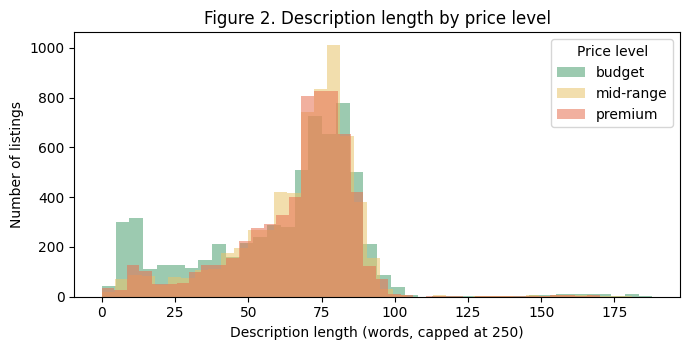

In [4]:
desc = df["description"].fillna("")
quality = pd.DataFrame({
    "modality": ["image", "text", "text", "tabular", "tabular", "tabular",
                 "tabular"],
    "column": ["picture_url", "description", "name", "bedrooms", "beds",
               "bathrooms_text", "review_scores_rating"],
})
quality["missing share"] = [
    df[c].isna().mean() if c in df else np.nan for c in quality["column"]
]
print("Table 2. Missing values by column")
save_table(quality.set_index("column").round(3), "T02_missing_values")

n_words = desc.str.split().str.len()
key = desc.str.lower().str.strip()
dup_share = key[key != ""].duplicated(keep=False).mean()
# Simple patterns for personal contact details inside the text
PII = {
    "email": r"[\w.+-]+@[\w-]+\.[\w.]+",
    "phone number": r"(?:\+?61|\b0)[\s-]?\d(?:[\s-]?\d){7,9}",
    "web link": r"https?://|www\.",
}
text_checks = pd.Series({
    "median description length (words)": n_words.median(),
    "descriptions under 10 words": (n_words < 10).mean(),
    "descriptions shared by 2+ listings": dup_share,
    "descriptions with HTML tags": desc.str.contains(r"<[^>]+>").mean(),
    "descriptions with non-English letters": desc.str.contains(
        r"[^\x00-\x7F‘’“”–—•]").mean(),
    **{f"descriptions with a possible {k}": desc.str.contains(p).mean()
       for k, p in PII.items()},
    "photo links shared by 2+ listings": df["picture_url"].duplicated(
        keep=False).mean(),
}, name="value").to_frame()
print("Table 3. Text and duplicate checks")
save_table(text_checks.round(4), "T03_text_quality")

fig, ax = plt.subplots(figsize=(7, 3.6))
for c, col in enumerate(CLASS_COLOURS):
    ax.hist(n_words[df["y"] == c].clip(upper=250), bins=40, alpha=0.55,
            color=col, label=CLASSES[c])
ax.set_xlabel("Description length (words, capped at 250)")
ax.set_ylabel("Number of listings")
ax.legend(title="Price level")
ax.set_title("Figure 2. Description length by price level")
plt.tight_layout()
save_fig(fig, "F02_description_length")

## 5. Preprocessing of each modality

**Text.**
* HTML tags such as `<br />` are removed, and HTML codes such as `&amp;` are changed back to normal characters (Week 2: cleaning text).
* Emails, phone numbers and web links are replaced with `[EMAIL]`, `[PHONE]` and `[LINK]`, so no contact details go into the model, as promised in the proposal.
* The title and the description are joined into one text, because the title often mentions useful things like the property type or the view.

**Tabular.**
* The number of bathrooms is read from text such as "1.5 shared baths", with an extra flag for a shared bathroom.
* Amenities are counted, and twelve common amenities that affect the price become yes/no columns.
* Some counts are very skewed (number of reviews, minimum nights), so they get a log transform.
* Missing values are filled with the median from the **training** set, plus a flag that shows the value was missing. This way the model can still use "no reviews yet", which usually means a new listing.
* Only the twelve most common property types are kept; all the others become "Other".

**Image.** Each photo is resized and normalised in the way the image encoder expects (Section 7.1).

I fit all scaling on the training set only, so no information from the validation or test set leaks into training (Weeks 6 and 7 practicals). I do this in Section 7.3.

In [5]:
def clean_text(text):
    """Remove HTML and personal contact details from a listing text."""
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(PII["email"], " [EMAIL] ", text)
    text = re.sub(PII["phone number"], " [PHONE] ", text)
    text = re.sub(r"(https?://|www\.)\S+", " [LINK] ", text)
    return re.sub(r"\s+", " ", text).strip()


df["text"] = (
    df["name"].fillna("").map(clean_text) + ". "
    + df["description"].fillna("").map(clean_text)
).str.strip(". ")
print("Example of a cleaned text:\n", df["text"].iloc[0][:300])

# Amenities that often change the price of a stay
AMENITY_WORDS = {
    "pool": "pool", "hot_tub": "hot tub", "gym": "gym",
    "parking": "parking", "air_con": "air conditioning",
    "dishwasher": "dishwasher", "washer": "washer", "dryer": "dryer",
    "view": "view", "bbq": "bbq", "workspace": "workspace",
    "balcony": "balcony",
}


def parse_amenities(s):
    """Amenities are stored as a JSON list in text."""
    try:
        return [a.lower() for a in json.loads(s)]
    except Exception:
        return []


amenity_lists = df["amenities"].map(parse_amenities)
tab = pd.DataFrame(index=df.index)
tab["accommodates"] = df["accommodates"]
tab["bedrooms"] = df["bedrooms"]
tab["beds"] = df["beds"]
bath = df["bathrooms_text"].fillna("").str.lower()
tab["bathrooms"] = pd.to_numeric(bath.str.extract(r"([\d.]+)")[0],
                                 errors="coerce")
tab.loc[bath.str.contains("half"), "bathrooms"] = 0.5
tab["shared_bath"] = bath.str.contains("shared").astype(float)
tab["n_amenities"] = amenity_lists.map(len)
for k, w in AMENITY_WORDS.items():
    tab[f"has_{k}"] = amenity_lists.map(
        lambda a, w=w: any(w in x for x in a)).astype(float)
tab["log_min_nights"] = np.log1p(df["minimum_nights"].clip(upper=365))
tab["availability_365"] = df["availability_365"]
tab["log_n_reviews"] = np.log1p(df["number_of_reviews"])
tab["review_score"] = df["review_scores_rating"]
tab["no_reviews_yet"] = df["review_scores_rating"].isna().astype(float)
tab["instant_bookable"] = (df["instant_bookable"] == "t").astype(float)
for c in ["bedrooms", "beds", "bathrooms"]:
    tab[f"{c}_missing"] = tab[c].isna().astype(float)

top_types = df["property_type"].value_counts().index[:12]
categories = pd.DataFrame({
    "room": df["room_type"],
    "type": df["property_type"].where(
        df["property_type"].isin(top_types), "Other"),
})
area = df["neighbourhood_cleansed"].fillna("Unknown")
X_cat = pd.get_dummies(categories, dtype=np.float32).values
X_area = pd.get_dummies(area, prefix="area", dtype=np.float32).values
print(f"Tabular: {tab.shape[1]} numeric columns, "
      f"{categories['room'].nunique()} room types, "
      f"{categories['type'].nunique()} property types, "
      f"{area.nunique()} areas")

Example of a cleaned text:
 555 swanston. good location
Tabular: 27 numeric columns, 4 room types, 13 property types, 30 areas


## 6. Grouped train, validation and test split (70/15/15)

Many listings use the same description, usually because one host has several similar units, and a few listings even use the same photo. This causes a problem. If one copy ends up in the training set and another copy in the test set, the model has already "seen" the test listing, so the test score looks better than it really is. This is called **leakage**.

To stop this, listings that share a description **or** a photo are put into one **group**, and each group goes completely into one set.

For the split I use `StratifiedGroupKFold` with 20 folds, which also keeps the three price levels balanced in every set. Three folds become the test set, three folds the validation set, and the other fourteen folds the training set (Week 7 practical: three sets, three jobs). The test set is only used once, for the final evaluation.

In [6]:
# Step 1: listings with the same description get the same group number
desc_key = df["description"].fillna("").str.lower().str.strip()
desc_key = desc_key.where(desc_key != "", "no_text_" + df["id"].astype(str))
groups = pd.Series(pd.factorize(desc_key)[0], index=df.index)
# Step 2: listings with the same photo join the group of the first one.
# I repeat this a few times, so chains of shared texts and photos end up
# in one group.
for _ in range(5):
    groups = groups.groupby(df["picture_url"].fillna("none")).transform("min")
    groups = groups.groupby(desc_key).transform("min")
groups = groups.values

sgkf = StratifiedGroupKFold(n_splits=CFG["n_folds"], shuffle=True,
                            random_state=SEED)
fold = np.zeros(len(df), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(df, df["y"], groups)):
    fold[idx] = k
split = np.where(fold < 3, "test", np.where(fold < 6, "val", "train"))
SPLIT = {s: np.where(split == s)[0] for s in ["train", "val", "test"]}
y_all = df["y"].values
Y = {s: y_all[i] for s, i in SPLIT.items()}
tr, va, te = SPLIT["train"], SPLIT["val"], SPLIT["test"]

split_table = pd.DataFrame({
    s: {"listings": len(i), "share": len(i) / len(df),
        **{c: (y_all[i] == k).mean() for k, c in enumerate(CLASSES)}}
    for s, i in SPLIT.items()
}).T
print("Table 4. The three sets and their class balance")
save_table(split_table.round(3), "T04_split")
shared = set(groups[tr]) & set(groups[te])
print(f"{len(np.unique(groups)):,} groups. Groups in both train and test: "
      f"{len(shared)} (must be 0)")

Table 4. The three sets and their class balance


,listings,share,budget,mid-range,premium
train,13228.0,0.703,0.337,0.332,0.331
val,2853.0,0.152,0.342,0.331,0.327
test,2732.0,0.145,0.308,0.345,0.347


16,268 groups. Groups in both train and test: 0 (must be 0)


## 7. Feature extraction

### 7.1 Image: download, quality check, EfficientNet-B0 and CLIP

Inside Airbnb does not keep the photos themselves, only a **link** to the main photo of each listing. So each photo is downloaded at 480 pixels wide, used straight away, and then thrown away. The photos are **not stored**, because they show people's private homes (see ethics, Section 13).

From every photo only three things are kept:
* The **EfficientNet-B0** features: 1,280 numbers from the model with ImageNet weights and the classifier removed (Week 4 practical, Assignment 2). This is the image encoder planned in the proposal.
* The **CLIP** ViT-B/32 image features: 512 numbers (Week 8). CLIP was first added only for comparison, but it did better on the validation set, so it is also used in the improved models (Section 9.4).
* A few simple **quality** numbers from the Week 2 lecture and demos: width to height ratio, brightness, contrast, entropy and sharpness (variance of the Laplacian).

Downloading almost 19,000 photos takes a long time, so the work is done in pieces of 1,024 listings and each piece is saved to Drive. If Colab disconnects, the download continues from the last saved piece.

In [7]:
SESSION = requests.Session()
SESSION.mount("https://", requests.adapters.HTTPAdapter(
    pool_connections=CFG["img_workers"], pool_maxsize=CFG["img_workers"]))


def fetch_image(url):
    """Download one photo in a small size; return a PIL image or None."""
    if not isinstance(url, str) or not url.startswith("http"):
        return None
    try:
        # Airbnb photos accept a width setting, so I ask for a small copy
        r = SESSION.get(url.split("?")[0] + f"?im_w={CFG['img_width']}",
                        timeout=20)
        r.raise_for_status()
        im = Image.open(io.BytesIO(r.content))
        im.load()
        im = im.convert("RGB")
        im.thumbnail((CFG["img_width"], CFG["img_width"]))
        return im
    except Exception:
        return None


QUALITY_COLS = ["width_height_ratio", "brightness", "contrast", "entropy",
                "sharpness"]


def image_quality(im):
    """No-reference quality numbers for one photo (Week 2 lecture/demos)."""
    g = np.asarray(im.convert("L"), dtype=np.float64)
    return [
        im.width / im.height,  # below 1 means a portrait photo
        g.mean() / 255,  # average brightness (0 = black, 1 = white)
        g.std() / 255,  # spread of brightness (overall contrast)
        shannon_entropy(g.astype(np.uint8)),  # how many grey levels are used
        laplace(g / 255.0).var() * 1e3,  # blur check: low = blurry
    ]


# EfficientNet-B0 without its last layer gives one 1,280-number vector
eff_weights = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1
effnet = torchvision.models.efficientnet_b0(weights=eff_weights)
effnet.classifier = nn.Identity()
effnet = effnet.eval().to(DEVICE)
eff_prep = eff_weights.transforms()  # resize, crop to 224, normalise

# CLIP image encoder (reference only)
from transformers import CLIPModel, CLIPImageProcessor  # noqa: E402

clip_model = CLIPModel.from_pretrained(CFG["clip_name"]).eval().to(DEVICE)
clip_prep = CLIPImageProcessor.from_pretrained(CFG["clip_name"])


@torch.no_grad()
def embed_images(images):
    """EfficientNet-B0 and CLIP features for a list of PIL images."""
    eff, clip = [], []
    for i in range(0, len(images), CFG["img_batch"]):
        batch = images[i:i + CFG["img_batch"]]
        x = torch.stack([eff_prep(im) for im in batch]).to(DEVICE)
        eff.append(effnet(x).cpu().numpy())
        px = clip_prep(images=batch, return_tensors="pt")["pixel_values"]
        out = clip_model.get_image_features(pixel_values=px.to(DEVICE))
        if not torch.is_tensor(out):  # newer library versions
            out = out.pooler_output
        clip.append(F.normalize(out, dim=1).cpu().numpy())
    return np.vstack(eff), np.vstack(clip)


def image_piece(k, urls):
    """Download, check and embed one piece of photos; save it to Drive."""
    path = FEAT_DIR / f"img_piece_{k:03d}.npz"
    if path.exists():  # already done in an earlier run
        return dict(np.load(path))
    with cf.ThreadPoolExecutor(CFG["img_workers"]) as pool:
        ims = list(pool.map(fetch_image, urls))
    ok = np.array([im is not None for im in ims])
    good = [im for im in ims if im is not None]
    n = len(urls)
    eff = np.zeros((n, 1280), np.float32)
    clip = np.zeros((n, 512), np.float32)
    qual = np.full((n, len(QUALITY_COLS)), np.nan, np.float32)
    if good:
        eff[ok], clip[ok] = embed_images(good)
        qual[ok] = np.array([image_quality(im) for im in good])
    out = {"ok": ok, "eff": eff, "clip": clip, "quality": qual}
    np.savez_compressed(path, **out)
    return out


# Safety check: saved pieces must belong to the same listings in the same
# order, otherwise the features would be matched to the wrong listing
ids_path = FEAT_DIR / "listing_ids.npy"
if ids_path.exists() and not np.array_equal(np.load(ids_path),
                                            df["id"].values):
    raise RuntimeError("The saved features belong to other listings. "
                       "Delete the features folder and run again.")
np.save(ids_path, df["id"].values)

urls = df["picture_url"].tolist()
t0 = time.time()
pieces = []
n_pieces = int(np.ceil(len(urls) / CFG["img_chunk"]))
for k in range(n_pieces):
    s = slice(k * CFG["img_chunk"], (k + 1) * CFG["img_chunk"])
    pieces.append(image_piece(k, urls[s]))
    print(f"\rPhoto piece {k + 1}/{n_pieces} done, {time.time() - t0:.0f} s",
          end="")
print()
img_ok = np.concatenate([p["ok"] for p in pieces])
X_eff = np.vstack([p["eff"] for p in pieces])
X_clip = np.vstack([p["clip"] for p in pieces])
img_q = pd.DataFrame(np.vstack([p["quality"] for p in pieces]),
                     columns=QUALITY_COLS)
TIMES = {"photo download and image features (s)": time.time() - t0}
print(f"Photos available: {img_ok.mean():.1%} of {len(img_ok):,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 152MB/s]


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Photo piece 19/19 done, 23 s
Photos available: 98.9% of 18,813


Table 5. Image quality checks


,share
photos that failed to download,0.0109
portrait photos (width/height < 0.9),0.1111
very dark photos (brightness < 0.25),0.0109
very bright photos (brightness > 0.85),0.0003
low contrast photos (contrast < 0.1),0.0007
"low entropy photos (entropy < 5, e.g. floor plans or text)",0.0054


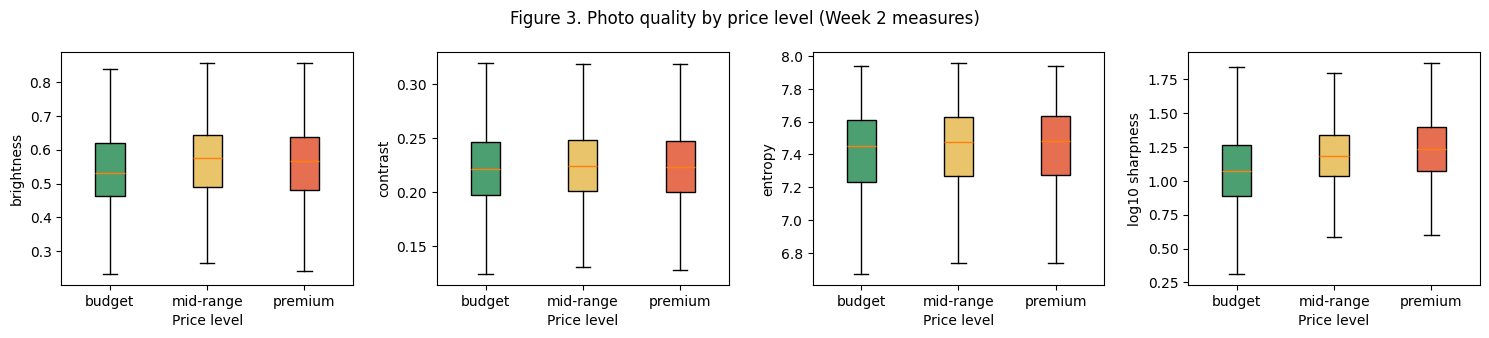

In [8]:
# Check photo quality and compare it across price levels
q = img_q[img_ok]
img_checks = pd.Series({
    "photos that failed to download": 1 - img_ok.mean(),
    "portrait photos (width/height < 0.9)": (q["width_height_ratio"]
                                             < 0.9).mean(),
    "very dark photos (brightness < 0.25)": (q["brightness"] < 0.25).mean(),
    "very bright photos (brightness > 0.85)": (q["brightness"]
                                               > 0.85).mean(),
    "low contrast photos (contrast < 0.1)": (q["contrast"] < 0.1).mean(),
    "low entropy photos (entropy < 5, e.g. floor plans or text)": (
        q["entropy"] < 5).mean(),
}, name="share").to_frame()
print("Table 5. Image quality checks")
save_table(img_checks.round(4), "T05_image_quality")

# One box plot per quality measure, split by price level
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
y_ok = df["y"].values[img_ok]
for ax, col in zip(axes, ["brightness", "contrast", "entropy",
                          "sharpness"]):
    data = [q[col].values[y_ok == c] for c in range(3)]
    if col == "sharpness":
        data = [np.log10(d + 1e-3) for d in data]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True)
    for patch, box_colour in zip(bp["boxes"], CLASS_COLOURS):
        patch.set_facecolor(box_colour)
    ax.set_xticks([1, 2, 3], CLASSES)
    ax.set_xlabel("Price level")
    ax.set_ylabel(("log10 " if col == "sharpness" else "") + col)
fig.suptitle("Figure 3. Photo quality by price level (Week 2 measures)")
plt.tight_layout()
save_fig(fig, "F03_image_quality")

### 7.2 Text: turning the descriptions into numbers with BERT

Each cleaned text goes through BERT (`bert-base-uncased`), which turns it into a list of 768 numbers that the models can use.

BERT gives one vector for every word piece in the text. To get one vector for the whole text, I take the **average of all the word vectors** and ignore the empty padding at the end. This is called mean pooling, and it is the main method, as in the Week 4 practical. I also keep the special **[CLS]** vector, because the brief allows either one, and Section 8 compares the two.

Very long texts are cut at 256 word pieces. In this data almost no text was that long, so nothing important is lost.

In [9]:
# Turn every text into BERT features (mean pooling and [CLS])
txt_path = FEAT_DIR / "bert_features.npz"
t0 = time.time()
if txt_path.exists():
    z = np.load(txt_path)
    X_bert, X_cls, cut_share = z["mean"], z["cls"], float(z["cut_share"])
else:
    tok = AutoTokenizer.from_pretrained(CFG["bert_name"])
    bert = AutoModel.from_pretrained(CFG["bert_name"]).eval().to(DEVICE)
    texts = df["text"].tolist()
    # how many texts are longer than the limit and will be cut
    lengths = np.array([len(t) for t in tok(texts)["input_ids"]])
    cut_share = float(np.mean(lengths > CFG["bert_max_len"]))
    mean_out, cls_out = [], []
    with torch.no_grad():
        for i in range(0, len(texts), CFG["bert_batch"]):
            t = tok(texts[i:i + CFG["bert_batch"]], padding=True,
                    truncation=True, max_length=CFG["bert_max_len"],
                    return_tensors="pt").to(DEVICE)
            h = bert(**t).last_hidden_state
            mask = t["attention_mask"].unsqueeze(-1).float()
            # mean of the real tokens only (padding has mask 0)
            mean_out.append(((h * mask).sum(1) / mask.sum(1)).cpu().numpy())
            cls_out.append(h[:, 0].cpu().numpy())  # the [CLS] token
    X_bert = np.vstack(mean_out).astype(np.float32)
    X_cls = np.vstack(cls_out).astype(np.float32)
    np.savez_compressed(txt_path, mean=X_bert, cls=X_cls, cut_share=cut_share)
    del bert
TIMES["text features (s)"] = time.time() - t0
print(f"BERT features: {X_bert.shape}. Texts cut at {CFG['bert_max_len']} "
      f"tokens: {cut_share:.1%}")

BERT features: (18813, 768). Texts cut at 256 tokens: 0.0%


### 7.3 Tabular features and preparing the inputs for each model

Everything the models learn from the data is learned from the **training set only** (Weeks 6 and 7 practicals). This includes the medians used to fill missing values, the scaling, and the PCA. This way the validation and test sets stay completely unseen.

The two types of models need the inputs in a slightly different form:
* **Tree models (XGBoost):** the image and text vectors are very long, so, as in Assignment 2, they are scaled and then made shorter with PCA. The best PCA size is chosen on the validation set (Section 9.1). An extra "photo missing" flag is added to the image part.
* **Attention network:** it uses the full scaled vectors, because each modality has its own small encoder that learns how to make the vector shorter (Assignment 2).

The same functions are used again later for the unseen areas test (Section 14), so the features there are built in exactly the same way.

In [10]:
# All the feature types, so the models can pick one by name
IMAGE_FEATS = {"eff": X_eff, "clip": X_clip}
TEXT_FEATS = {"mean": X_bert, "cls": X_cls}
# 1 if the photo is missing, 0 if it downloaded
img_missing = (~img_ok).astype(np.float32)[:, None]


def scaled(X, train_rows):
    """Standardise with the mean and std of the training rows only."""
    return StandardScaler().fit(X[train_rows]).transform(X).astype(np.float32)


def tabular_matrix(train_rows, with_area=True):
    """Fill missing values with training medians, scale, add categories."""
    filled = tab.fillna(tab.iloc[train_rows].median())
    parts = [scaled(filled.values.astype(np.float32), train_rows), X_cat]
    if with_area:
        parts.append(X_area)
    return np.hstack(parts).astype(np.float32)


_cache = {}


def tree_blocks(train_rows, n_pca, image="eff", text="mean", with_area=True,
                tag="main"):
    """Image, text and tabular blocks for the tree models (cached)."""
    key = (tag, n_pca, image, text, with_area)
    if key not in _cache:
        def reduce(X):
            # scale, then make the vector shorter with PCA
            # (PCA is fitted on the training rows only)
            Xs = scaled(X, train_rows)
            return PCA(n_components=n_pca, random_state=SEED).fit(
                Xs[train_rows]).transform(Xs).astype(np.float32)

        _cache[key] = {
            "image": np.hstack([reduce(IMAGE_FEATS[image]), img_missing]),
            "text": reduce(TEXT_FEATS[text]),
            "tabular": tabular_matrix(train_rows, with_area),
        }
    return _cache[key]


def joined(B, mods=MODS):
    """Early fusion input: the blocks side by side (concatenation)."""
    return np.hstack([B[m] for m in mods])

## 8. Which feature extractor? (validation comparison)

Before building the fusion models, I check which feature extractor works better for each modality. For this I train a simple XGBoost model on one modality at a time and compare the scores on the **validation** set, with 3 seeds:
* Image: **EfficientNet-B0** (planned in the proposal) or **CLIP** (a newer, state of the art model).
* Text: BERT with **mean pooling** (planned in the proposal) or BERT **[CLS]**.

The test set is not used here. The planned fusion models keep EfficientNet-B0 and mean pooling, as in the proposal. CLIP scored better on validation, so it is used later in the improved models (Section 9.4).

In [11]:
def make_xgb(max_depth=4, learning_rate=0.05, seed=SEED):
    """One XGBoost classifier with the settings shared by all tree models."""
    return xgb.XGBClassifier(
        # Upper limit only; early stopping picks the real number of trees
        n_estimators=2000,
        # Tree depth sets how many features one tree can combine
        max_depth=max_depth,
        learning_rate=learning_rate,
        # Each tree sees 80% of the rows, which reduces overfitting
        subsample=0.8,
        # Each tree sees 60% of the columns, so one modality cannot take over
        colsample_bytree=0.6,
        min_child_weight=3,
        reg_lambda=1.0,
        # Output class probabilities for the 3 classes
        objective="multi:softprob",
        eval_metric="mlogloss",
        early_stopping_rounds=50,
        tree_method="hist",
        device="cuda" if DEVICE.type == "cuda" else "cpu",
        random_state=seed,
        n_jobs=-1,
    )


def fit_xgb(X, params, seed=SEED, S=None):
    """Train on the training rows, early stopping on the validation rows."""
    S = S or SPLIT
    m = make_xgb(seed=seed, **params)
    m.fit(X[S["train"]], y_all[S["train"]],
          eval_set=[(X[S["train"]], y_all[S["train"]]),
                    (X[S["val"]], y_all[S["val"]])],
          verbose=False)
    return m


def proba(m, X, rows):
    """Class probabilities for some rows (made to sum exactly to 1)."""
    p = m.predict_proba(X[rows]).astype(np.float64)
    return p / p.sum(1, keepdims=True)


BASE_PARAMS = {"max_depth": 4, "learning_rate": 0.05}
rows = []
for name, mod, image, text in [
    ("Image: EfficientNet-B0", "image", "eff", "mean"),
    ("Image: CLIP ViT-B/32 (reference)", "image", "clip", "mean"),
    ("Text: BERT mean pooling", "text", "eff", "mean"),
    ("Text: BERT [CLS]", "text", "eff", "cls"),
]:
    B = tree_blocks(tr, 64, image=image, text=text)
    f1s = [f1_score(Y["val"], proba(fit_xgb(B[mod], BASE_PARAMS, s), B[mod],
                                    va).argmax(1), average="macro")
           for s in SEEDS]
    rows.append({"feature extractor": name, "val macro F1 (mean)":
                 np.mean(f1s), "std over seeds": np.std(f1s)})
extractor_table = pd.DataFrame(rows).set_index("feature extractor")
print("Table 6. Feature extractors, single-modality model, validation set")
save_table(extractor_table.round(3), "T06_feature_extractors")

Table 6. Feature extractors, single-modality model, validation set


,val macro F1 (mean),std over seeds
feature extractor,,
Image: EfficientNet-B0,0.510,0.003
Image: CLIP ViT-B/32 (reference),0.548,0.003
Text: BERT mean pooling,0.575,0.005
Text: BERT [CLS],0.549,0.003


## 9. Models

All the models use the same features and the same train, validation and test split. This means any difference in the results comes only from **how** the modalities are combined.

| Approach | Where the modalities are combined | Model | Course link |
|---|---|---|---|
| Image / Text / Tabular only | not combined (baseline) | XGBoost on one modality | Week 4 |
| Early fusion | at the start, by joining the features | one XGBoost on all features together | Week 4 lecture, Assignment 2 |
| Late fusion | at the end, by joining the predictions | weighted average of the three single-modality models; the weights are chosen on validation | Week 4 lecture, Assignment 2 |
| Attention fusion | in the middle of the network | each modality becomes one token, plus a [CLS] token, joined with multi-head attention | Week 5 lecture and practical, Assignment 2 |

Every model is trained 3 times with different seeds, and the tables show the average and the standard deviation (Week 7 practical).

### 9.1 Tree settings, chosen on the validation set (3 seeds)

As in the Week 7 practical solution, each setting is trained with 3 seeds. Then I compare two things: how much the score changes between settings, and how much it changes between seeds. If these two are about the same, the setting does not really matter. This is a normal result and still useful to report.

In [12]:
# Try every tree setting with 3 seeds on the early fusion input
rows = []
t0 = time.time()
g = CFG["xgb_grid"]
for n_pca in g["n_pca"]:
    X = joined(tree_blocks(tr, n_pca))
    for d in g["max_depth"]:
        for lr in g["learning_rate"]:
            for s in SEEDS:
                m = fit_xgb(X, {"max_depth": d, "learning_rate": lr}, s)
                p = proba(m, X, va)
                rows.append({"PCA components": n_pca, "tree depth": d,
                             "learning rate": lr, "seed": s,
                             "trees used": m.best_iteration + 1,
                             "val log loss": log_loss(Y["val"], p),
                             "val macro F1": f1_score(Y["val"], p.argmax(1),
                                                      average="macro")})
TIMES["tree settings search (s)"] = time.time() - t0
# Average over the 3 seeds and sort, best setting first
sweep = pd.DataFrame(rows)
xgb_sweep = sweep.groupby(["PCA components", "tree depth", "learning rate"])[
    ["trees used", "val log loss", "val macro F1"]].agg(["mean", "std"])
xgb_sweep = xgb_sweep.sort_values(("val log loss", "mean"))
print("Table 7. Tree settings (early fusion), validation set, 3 seeds")
save_table(xgb_sweep.round(4), "T07_xgb_sweep")
# Keep the setting with the lowest validation log loss
best = xgb_sweep.index[0]
N_PCA = int(best[0])
XGB_PARAMS = {"max_depth": int(best[1]), "learning_rate": float(best[2])}
# Compare the gap between settings with the gap between seeds (Week 7)
f1_means = xgb_sweep[("val macro F1", "mean")]
print(f"Chosen by lowest validation log loss: {N_PCA} PCA components, "
      f"{XGB_PARAMS}")
print(f"Gap between best and worst setting (macro F1): "
      f"{f1_means.max() - f1_means.min():.3f}; typical std over seeds: "
      f"{xgb_sweep[('val macro F1', 'std')].mean():.3f}")
BLOCKS = tree_blocks(tr, N_PCA)

Table 7. Tree settings (early fusion), validation set, 3 seeds


trees used          val log loss  \
                                              mean      std         mean   
PCA components tree depth learning rate                                    
32             4          0.05            486.0000  55.4887       0.6511   
               6          0.05            259.6667   8.3865       0.6520   
               4          0.10            247.6667  29.3655       0.6526   
64             4          0.05            448.0000  54.0833       0.6529   
               6          0.05            278.3333  17.0978       0.6532   
32             6          0.10            119.6667  23.2881       0.6540   
64             4          0.10            233.3333  45.7639       0.6555   
               6          0.10            123.0000  13.8924       0.6571   

                                                val macro F1          
                                            std         mean     std  
PCA components tree depth learning rate                               
32             4          0.05           0.0013       0.6988  0.0027  
               6          0.05           0.0035       0.7024  0.0037  
               4          0.10           0.0007       0.6992  0.0021  
64             4          0.05           0.0015       0.7000  0.0018  
               6          0.05           0.0011       0.6981  0.0049  
32             6          0.10           0.0023       0.7014  0.0027  
64             4          0.10           0.0015       0.6969  0.0014  
               6          0.10           0.0024       0.6944  0.0030

Chosen by lowest validation log loss: 32 PCA components, {'max_depth': 4, 'learning_rate': 0.05}
Gap between best and worst setting (macro F1): 0.008; typical std over seeds: 0.003


### 9.2 Single-modality baselines, early fusion and late fusion

**Early fusion** joins the three blocks into one vector, z = g([x_image, x_text, x_tabular]), and trains one model (Week 4 lecture).

**Late fusion** trains one model per modality and combines their class probabilities at the decision level (Week 4 lecture):

p = w_image · p_image + w_text · p_text + w_tabular · p_tabular, with every w ≥ 0 and the weights summing to 1.

The weights are searched on a 0.05 grid using the validation log loss. The three single-modality models are also the baselines, so the baselines and late fusion use exactly the same models. I also compare the combination rules from the Week 4 lecture (equal weights and majority voting) on the validation set.

In [13]:
def combine(P, w):
    """Weighted average of per-modality probabilities (Week 4 lecture)."""
    w = np.asarray(w, float) / np.sum(w)
    return sum(wi * pi for wi, pi in zip(w, P))


def search_weights(P_val, y_val, step=0.05):
    """Try every weight combination on the grid (weights sum to 1)."""
    best_w, best_loss = None, np.inf
    grid = np.round(np.arange(0, 1 + 1e-9, step), 2)
    for a in grid:
        for b in grid:
            c = round(1 - a - b, 2)  # the third weight is what is left
            if c < -1e-9:
                continue
            loss = log_loss(y_val, combine(P_val, [a, b, c]))
            if loss < best_loss:
                best_w, best_loss = np.array([a, b, c]), loss
    return best_w


def majority_vote(P):
    """Each model votes for its class; a three-way tie goes to the most
    confident model."""
    votes = np.stack([p.argmax(1) for p in P], 1)
    out = []
    for i, v in enumerate(votes):
        counts = np.bincount(v, minlength=3)
        if counts.max() >= 2:
            out.append(counts.argmax())
        else:
            out.append(v[np.argmax([p[i].max() for p in P])])
    return np.array(out)


def run_trees(B, S=None, seeds=SEEDS):
    """Baselines, early fusion and late fusion for each seed.

    Returns the probabilities for every split, the fitted models of the
    first seed, the late fusion weights and the training times.
    """
    S = S or SPLIT
    probs, models, weights, times = {}, {}, [], {}
    for s in seeds:
        for mod in MODS:
            name = f"{mod.capitalize()} only"
            t0 = time.time()
            m = fit_xgb(B[mod], XGB_PARAMS, s, S)
            times.setdefault(name, []).append(time.time() - t0)
            probs.setdefault(name, []).append(
                {k: proba(m, B[mod], rows) for k, rows in S.items()})
            if s == seeds[0]:
                models[name] = m
        t0 = time.time()
        m = fit_xgb(joined(B), XGB_PARAMS, s, S)
        times.setdefault("Early fusion", []).append(time.time() - t0)
        probs.setdefault("Early fusion", []).append(
            {k: proba(m, joined(B), rows) for k, rows in S.items()})
        if s == seeds[0]:
            models["Early fusion"] = m
        P_each = [probs[f"{mod.capitalize()} only"][-1] for mod in MODS]
        w = search_weights([p["val"] for p in P_each], y_all[S["val"]])
        weights.append(w)
        probs.setdefault("Late fusion", []).append(
            {k: combine([p[k] for p in P_each], w) for k in S})
        times.setdefault("Late fusion", []).append(
            sum(times[f"{mod.capitalize()} only"][-1] for mod in MODS))
    return probs, models, weights, times


PROBS, TREES, LATE_W, TRAIN_TIME = run_trees(BLOCKS)
late_w = pd.DataFrame(LATE_W, columns=[f"weight {m}" for m in MODS],
                      index=[f"seed {s}" for s in SEEDS])
print("Late fusion weights learned on the validation set:")
display(late_w.round(2))

# Combination rules from the Week 4 lecture, validation set, first seed
P_val = [PROBS[f"{m.capitalize()} only"][0]["val"] for m in MODS]
rules = pd.DataFrame({
    "equal weights (1/3 each)": f1_score(
        Y["val"], combine(P_val, [1, 1, 1]).argmax(1), average="macro"),
    "majority voting": f1_score(Y["val"], majority_vote(P_val),
                                average="macro"),
    "learned weights": f1_score(
        Y["val"], combine(P_val, LATE_W[0]).argmax(1), average="macro"),
}, index=["val macro F1"]).T
print("Table 8. Late fusion combination rules (validation, first seed)")
save_table(rules.round(3), "T08_late_fusion_rules")

Late fusion weights learned on the validation set:


,weight image,weight text,weight tabular
seed 42,0.0,0.05,0.95
seed 43,0.0,0.05,0.95
seed 44,0.0,0.05,0.95


Table 8. Late fusion combination rules (validation, first seed)


,val macro F1
equal weights (1/3 each),0.700
majority voting,0.651
learned weights,0.701


### 9.3 Attention-based fusion

This is the attention model from Assignment 2, based on the Week 5 lecture and practical. It works in four steps:
1. Each modality goes through its own small **encoder** (two layers), which turns it into one vector of the same size. I call this vector a **token**, so each listing has three tokens: image, text and tabular.
2. An extra learnable **[CLS] token** is added, and each token gets a small **modality embedding** so the model knows which token is which.
3. A **multi-head attention** block lets every token look at the other tokens and share information. After it there is a feed-forward layer that is 4 times wider (Week 5 practical).
4. The final **[CLS]** vector is used to predict the price level.

Two extra details for real data:
* **Missing photos** are hidden from the attention (`key_padding_mask`), so the model does not treat an empty vector as a real photo.
* **Modality dropout:** during training, each modality is hidden 10% of the time. This forces the model to use all modalities and not depend on only one (Week 5 practical; Week 7 lecture on modality dominance).

Training follows the Week 6 and 7 practicals: Adam with learning rate 0.001 and weight decay 0.0001, up to 60 epochs, dropout, and **early stopping**, which keeps the weights from the epoch with the lowest validation loss. I use a batch size of 256 instead of 32 from the practicals, because I have about 13,000 training listings, so a bigger batch keeps training fast on a free GPU.

In [14]:
class AttentionFusionNet(nn.Module):
    """Attention-based intermediate fusion of image, text and tabular data.

    Each modality becomes one token, a [CLS] token is added, and one
    multi-head attention block lets every token look at every other token.
    The [CLS] output is classified into the 3 price levels.
    """

    def __init__(self, dims, hidden_dim=128, num_heads=4, dropout=0.3,
                 modality_dropout=0.1, n_classes=3, aux_heads=False):
        super().__init__()
        self.modality_dropout = modality_dropout

        def encoder(in_dim):
            """Two-layer projection into the shared hidden space."""
            return nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.ReLU(),
                                 nn.Dropout(dropout),
                                 nn.Linear(hidden_dim, hidden_dim))

        # One encoder per modality, each with its own weights
        self.encoders = nn.ModuleList([encoder(d) for d in dims])

        self.aux_heads = nn.ModuleList(
            [nn.Linear(hidden_dim, n_classes) for _ in dims]) \
            if aux_heads else None

        self.cls_token = nn.Parameter(torch.randn(1, 1, hidden_dim) * 0.02)
        self.modality_embedding = nn.Parameter(
            torch.randn(1, len(dims) + 1, hidden_dim) * 0.02)
        # Multi-head attention for cross-modal fusion
        self.attn = nn.MultiheadAttention(hidden_dim, num_heads,
                                          dropout=dropout, batch_first=True)
        self.norm_attn = nn.LayerNorm(hidden_dim)
        # Feed-forward layer with the usual 4x expansion (Week 5 practical)
        self.ff = nn.Sequential(nn.Linear(hidden_dim, 4 * hidden_dim),
                                nn.ReLU(), nn.Dropout(dropout),
                                nn.Linear(4 * hidden_dim, hidden_dim))
        self.norm_ff = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        # Classifier on the [CLS] token
        self.classifier = nn.Sequential(nn.Linear(hidden_dim, hidden_dim),
                                        nn.ReLU(), nn.Dropout(dropout),
                                        nn.Linear(hidden_dim, n_classes))

    def forward(self, xs, missing, return_parts=False):
        """xs: list of [batch, dim] tensors; missing: [batch, 3] (True = gone).

        Returns the class scores (logits) and the attention of [CLS] on
        each modality token. With return_parts=True it also returns the
        modality tokens and the fused [CLS] vector (used for CKA).
        """
        tokens = torch.stack([enc(x) for enc, x in zip(self.encoders, xs)],
                             dim=1)
        if self.training and self.modality_dropout > 0:
            # Modality dropout: hide random modalities during training
            hide = torch.rand(missing.shape, device=missing.device) \
                < self.modality_dropout
            missing = missing | hide
        # Never hide every modality of one listing
        missing = missing & ~missing.all(1, keepdim=True)
        # Keep the tokens and the mask for the auxiliary losses
        self.last_tokens, self.last_missing = tokens, missing
        b = tokens.shape[0]
        h = torch.cat([self.cls_token.expand(b, -1, -1), tokens], 1)
        h = h + self.modality_embedding
        # [CLS] is never masked; a missing modality is masked out
        pad = torch.cat([torch.zeros(b, 1, dtype=torch.bool,
                                     device=h.device), missing], 1)
        a, w = self.attn(h, h, h, key_padding_mask=pad, need_weights=True)
        h = self.norm_attn(h + self.dropout(a))
        h = self.norm_ff(h + self.dropout(self.ff(h)))
        logits = self.classifier(h[:, 0])
        if return_parts:
            return logits, w[:, 0, 1:], tokens, h[:, 0]
        return logits, w[:, 0, 1:]


class GatedFusionNet(nn.Module):
    """Gated fusion (Week 4 lecture): learned gates decide, for every
    listing, how much to trust each modality.

    fused = g_image * h_image + g_text * h_text + g_tabular * h_tabular,
    where the gates g are a softmax over the modalities (they sum to 1).
    """

    def __init__(self, dims, hidden_dim=128, num_heads=4, dropout=0.3,
                 modality_dropout=0.1, n_classes=3, aux_heads=False):
        super().__init__()
        self.modality_dropout = modality_dropout

        def encoder(in_dim):
            """Two-layer projection into the shared hidden space."""
            return nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.ReLU(),
                                 nn.Dropout(dropout),
                                 nn.Linear(hidden_dim, hidden_dim))

        self.encoders = nn.ModuleList([encoder(d) for d in dims])
        self.aux_heads = nn.ModuleList(
            [nn.Linear(hidden_dim, n_classes) for _ in dims]) \
            if aux_heads else None
        # The gate network looks at all modalities and gives one score
        # per modality (num_heads is not used; kept for the same interface)
        self.gate = nn.Sequential(
            nn.Linear(hidden_dim * len(dims), hidden_dim), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, len(dims)))
        self.classifier = nn.Sequential(nn.Linear(hidden_dim, hidden_dim),
                                        nn.ReLU(), nn.Dropout(dropout),
                                        nn.Linear(hidden_dim, n_classes))

    def forward(self, xs, missing, return_parts=False):
        """Returns the class scores (logits) and the gate of each modality."""
        tokens = torch.stack([enc(x) for enc, x in zip(self.encoders, xs)],
                             dim=1)
        if self.training and self.modality_dropout > 0:
            hide = torch.rand(missing.shape, device=missing.device) \
                < self.modality_dropout
            missing = missing | hide
        missing = missing & ~missing.all(1, keepdim=True)
        self.last_tokens, self.last_missing = tokens, missing
        scores = self.gate(tokens.flatten(1))
        # A missing modality gets gate 0
        scores = scores.masked_fill(missing, float("-inf"))
        gates = F.softmax(scores, dim=1)
        fused = (gates.unsqueeze(-1) * tokens).sum(1)
        logits = self.classifier(fused)
        if return_parts:
            return logits, gates, tokens, fused
        return logits, gates


def nn_inputs(S=None, image="eff", with_area=True):
    """Tensors for the attention network for every split.

    The full vectors are standardised with training statistics only.
    """
    S = S or SPLIT
    Xi = scaled(IMAGE_FEATS[image], S["train"])
    Xt = scaled(X_bert, S["train"])
    Xb = tabular_matrix(S["train"], with_area)
    D = {}
    for k, rows in S.items():
        miss = np.zeros((len(rows), 3), bool)
        miss[:, 0] = ~img_ok[rows]  # a missing photo is masked out
        D[k] = {"xs": [torch.tensor(a[rows], device=DEVICE)
                       for a in (Xi, Xt, Xb)],
                "missing": torch.tensor(miss, device=DEVICE),
                "y": torch.tensor(y_all[rows], device=DEVICE)}
    return D


@torch.no_grad()
def att_predict(model, D, k, hide=None, xs=None):
    """Probabilities and [CLS] attention weights for split k.

    hide: list of modality positions to mask (missing-modality test).
    xs: replacement inputs (shuffle and noise tests).
    """
    model.eval()
    miss = D[k]["missing"].clone()
    if hide is not None:
        miss[:, hide] = True
    logits, w = model(xs if xs is not None else D[k]["xs"], miss)
    # Softmax turns the class scores into probabilities
    return F.softmax(logits, 1).cpu().numpy().astype(np.float64), \
        w.cpu().numpy()


def train_attention(D, hidden_dim=128, dropout=0.3, seed=SEED, lr=None,
                    aux_weight=0.0, model_cls=None):
    """Training loop in the style of the Week 6 and 7 practicals.

    Trains for 60 epochs with mini-batches, records the training and
    validation loss after every epoch, and at the end keeps the weights
    from the epoch with the lowest validation loss (early stopping).

    lr, aux_weight and model_cls are only changed in Section 9.4:
    aux_weight > 0 adds one extra loss per modality (Section 9.4).
    """
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    dims = [x.shape[1] for x in D["train"]["xs"]]
    model_cls = model_cls or AttentionFusionNet
    model = model_cls(dims, hidden_dim, CFG["att_heads"], dropout,
                      CFG["att_modality_dropout"],
                      aux_heads=aux_weight > 0).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr or CFG["att_lr"],
                                 weight_decay=CFG["att_weight_decay"])
    criterion = nn.CrossEntropyLoss()
    history = {"train loss": [], "val loss": [], "train F1": [],
               "val F1": []}
    best = {"loss": float("inf")}
    d = D["train"]
    n = len(d["y"])
    for epoch in range(CFG["att_epochs"]):
        # ---------- train ----------
        model.train()
        order = torch.randperm(n, generator=gen).to(DEVICE)
        for i in range(0, n, CFG["att_batch"]):
            idx = order[i:i + CFG["att_batch"]]
            optimizer.zero_grad()
            logits, _ = model([x[idx] for x in d["xs"]], d["missing"][idx])
            loss = criterion(logits, d["y"][idx])
            if aux_weight > 0:
                # Auxiliary losses: each modality token must also predict
                # the price level on its own, so no modality is ignored
                aux = []
                for j, head in enumerate(model.aux_heads):
                    keep = ~model.last_missing[:, j]
                    if keep.any():
                        aux.append(criterion(
                            head(model.last_tokens[keep, j]),
                            d["y"][idx][keep]))
                loss = loss + aux_weight * torch.stack(aux).mean()
            loss.backward()
            optimizer.step()
        # ---------- evaluate ----------
        for k in ["train", "val"]:
            p, _ = att_predict(model, D, k)
            yk = D[k]["y"].cpu().numpy()
            history[f"{k} loss"].append(log_loss(yk, p, labels=[0, 1, 2]))
            history[f"{k} F1"].append(f1_score(yk, p.argmax(1),
                                               average="macro"))

        if history["val loss"][-1] < best["loss"]:
            best = {"loss": history["val loss"][-1], "epoch": epoch,
                    "state": copy.deepcopy(model.state_dict())}
    model.load_state_dict(best["state"])
    model.eval()
    model.best_epoch = best["epoch"]
    return model, history


D_att = nn_inputs()
rows = []
t0 = time.time()
for hd in CFG["att_grid"]["hidden_dim"]:
    for dr in CFG["att_grid"]["dropout"]:
        for s in SEEDS:
            m, h = train_attention(D_att, hd, dr, s)
            rows.append({"hidden size": hd, "dropout": dr, "seed": s,
                         "best epoch": m.best_epoch,
                         "val log loss": min(h["val loss"]),
                         "val macro F1": h["val F1"][m.best_epoch]})
TIMES["attention settings search (s)"] = time.time() - t0
att_sweep = pd.DataFrame(rows).groupby(["hidden size", "dropout"])[
    ["best epoch", "val log loss", "val macro F1"]].agg(["mean", "std"])
att_sweep = att_sweep.sort_values(("val log loss", "mean"))
print("Table 9. Attention fusion settings, validation set, 3 seeds")
save_table(att_sweep.round(4), "T09_attention_sweep")
ATT_PARAMS = {"hidden_dim": int(att_sweep.index[0][0]),
              "dropout": float(att_sweep.index[0][1])}
print("Chosen by lowest validation log loss:", ATT_PARAMS)

ATT_MODELS, ATT_HIST = [], []
for s in SEEDS:
    t0 = time.time()
    m, h = train_attention(D_att, seed=s, **ATT_PARAMS)
    TRAIN_TIME.setdefault("Attention fusion", []).append(time.time() - t0)
    ATT_MODELS.append(m)
    ATT_HIST.append(h)
    PROBS.setdefault("Attention fusion", []).append(
        {k: att_predict(m, D_att, k)[0] for k in SPLIT})
N_PARAMS = sum(p.numel() for p in ATT_MODELS[0].parameters())
print(f"Attention fusion: {N_PARAMS:,} parameters; best epochs "
      f"{[m.best_epoch for m in ATT_MODELS]}")

Table 9. Attention fusion settings, validation set, 3 seeds


best epoch         val log loss         val macro F1  \
                          mean     std         mean     std         mean   
hidden size dropout                                                        
128         0.4         3.3333  1.1547       0.6720  0.0093       0.6966   
            0.2         1.0000  0.0000       0.6722  0.0117       0.6917   
256         0.2         1.0000  1.0000       0.6731  0.0221       0.6919   
            0.4         2.6667  2.0817       0.6743  0.0133       0.6930   

                             
                        std  
hidden size dropout          
128         0.4      0.0073  
            0.2      0.0075  
256         0.2      0.0141  
            0.4      0.0042

Chosen by lowest validation log loss: {'hidden_dim': 128, 'dropout': 0.4}
Attention fusion: 537,347 parameters; best epochs [4, 2, 4]


### 9.4 Improvements motivated by the first results

The first results (Sections 10 to 12) showed two problems. First, the fusion models were only a little better than the tabular model alone. Second, the tabular data **dominated**: late fusion gave the photo a weight of 0, so the photo was not used at all. The course teaches several ways to handle this, so I try them here. Every choice is made on the **validation set**, and the test set is still used only once, at the very end (Week 7 practical).

1. **A better image encoder.** Table 6 shows that CLIP image features score higher than EfficientNet-B0 on the validation set. CLIP (Radford et al., 2021) was trained to match images with their text descriptions using a contrastive loss (Week 8 lecture and practical). The EfficientNet-B0 models stay as the planned models from the proposal, and the CLIP versions are shown as improvements.
2. **Stacking** (Week 4 lecture: "a combination rule is learnt through a model"). Instead of fixed late fusion weights, a logistic regression learns how best to combine the three single-modality models. It is trained on the validation predictions, because the base models never saw the validation set.
3. **Gated fusion** (Week 4 lecture). The model learns a gate for each modality, which decides how much to trust that modality for each listing.
4. **Auxiliary losses** (Week 5 lecture: the loss can combine several losses; Week 7 lecture: a separate loss for each modality helps against modality dominance). Each modality token must also predict the price level on its own, so the network cannot simply ignore the photo or the text.
5. **A smaller learning rate** for the neural models, because in Table 9 they reached their best validation loss after only 1 to 4 epochs, which suggests they learned too fast.
6. **A fusion ensemble** (Week 4 lecture: averaging at the decision level; Week 5 lecture: ensembles). This is the average of the best tree model, the stacking model and the best neural fusion model.

At the end, the final model is the one with the highest macro F1 on the validation set.

In [15]:
IMG = "clip" if extractor_table.iloc[1, 0] > extractor_table.iloc[0, 0] \
    else "eff"
IMG_NAME = {"clip": "CLIP", "eff": "EfficientNet"}[IMG]
print(f"Image encoder chosen on the validation set: {IMG_NAME}")
B_imp = tree_blocks(tr, N_PCA, image=IMG)
D_imp = nn_inputs(image=IMG)

#the tree models with the better image encoder
P_imp, TREES_IMP, LATE_W_IMP, T_imp = run_trees(B_imp)
for m in ["Image only", "Early fusion", "Late fusion"]:
    PROBS[f"{m} ({IMG_NAME})"] = P_imp[m]
    TRAIN_TIME[f"{m} ({IMG_NAME})"] = T_imp[m]

# stacking: a logistic regression on the log probabilities of the
# three single-modality models, trained on the validation set
STACK = f"Stacking ({IMG_NAME})"
for s_i, s in enumerate(SEEDS):
    feats = {k: np.log(np.hstack([P_imp[f"{m.capitalize()} only"][s_i][k]
                                  for m in MODS]) + 1e-9) for k in SPLIT}
    meta = LogisticRegression(max_iter=1000, C=1.0)
    meta.fit(feats["val"], Y["val"])
    out = {k: meta.predict_proba(feats[k]) for k in ["train", "test"]}
    # validation predictions from 5-fold cross-validation, so the
    # validation score of stacking is not too optimistic
    out["val"] = cross_val_predict(
        LogisticRegression(max_iter=1000, C=1.0), feats["val"], Y["val"],
        cv=5, method="predict_proba")
    PROBS.setdefault(STACK, []).append(out)

# (3)-(5) attention and gated fusion: learning rate and auxiliary losses,
# chosen on the validation set (3 seeds each)
rows, NN_RUNS = [], {}
t0 = time.time()
for cls_name, cls in [("Attention fusion", AttentionFusionNet),
                      ("Gated fusion", GatedFusionNet)]:
    for lr in CFG["imp_lr"]:
        for aux in CFG["imp_aux_weight"]:
            runs = []
            for s in SEEDS:
                m, h = train_attention(D_imp, seed=s, lr=lr, aux_weight=aux,
                                       model_cls=cls, **ATT_PARAMS)
                runs.append({k: att_predict(m, D_imp, k)[0] for k in SPLIT})
                rows.append({"model": cls_name, "learning rate": lr,
                             "auxiliary loss weight": aux, "seed": s,
                             "best epoch": m.best_epoch,
                             "val log loss": min(h["val loss"]),
                             "val macro F1": h["val F1"][m.best_epoch]})
            NN_RUNS[(cls_name, lr, aux)] = runs
TIMES["improved neural models search (s)"] = time.time() - t0
imp_sweep = pd.DataFrame(rows).groupby(
    ["model", "learning rate", "auxiliary loss weight"])[
    ["best epoch", "val log loss", "val macro F1"]].agg(["mean", "std"])
print(f"Table 9b. Attention and gated fusion with {IMG_NAME} images: "
      "learning rate and auxiliary losses (validation, 3 seeds)")
save_table(imp_sweep.round(4), "T09b_improved_neural_sweep")

NEURAL_IMP = []
for cls_name in ["Attention fusion", "Gated fusion"]:
    sub = imp_sweep.loc[cls_name].sort_values(("val log loss", "mean"))
    lr, aux = sub.index[0]
    name = f"{cls_name}, tuned ({IMG_NAME})"
    PROBS[name] = NN_RUNS[(cls_name, lr, aux)]
    NEURAL_IMP.append(name)
    print(f"{name}: learning rate {lr}, auxiliary loss weight {aux}")
best_neural = min(NEURAL_IMP, key=lambda m: np.mean(
    [log_loss(Y["val"], r["val"]) for r in PROBS[m]]))

# (6) fusion ensemble: average of the three kinds of fusion, per seed
ENS = f"Fusion ensemble ({IMG_NAME})"
for s_i in range(len(SEEDS)):
    parts = [PROBS[f"Early fusion ({IMG_NAME})"][s_i], PROBS[STACK][s_i],
             PROBS[best_neural][s_i]]
    PROBS.setdefault(ENS, []).append(
        {k: np.mean([p[k] for p in parts], axis=0) for k in SPLIT})

IMPROVED = [f"Image only ({IMG_NAME})", f"Early fusion ({IMG_NAME})",
            f"Late fusion ({IMG_NAME})", STACK] + NEURAL_IMP + [ENS]
IMPROVED_FUSION = IMPROVED[1:]
selection = pd.DataFrame({
    m: {"val macro F1 (mean)": np.mean(
        [f1_score(Y["val"], r["val"].argmax(1), average="macro")
         for r in PROBS[m]]),
        "val macro F1 (std)": np.std(
        [f1_score(Y["val"], r["val"].argmax(1), average="macro")
         for r in PROBS[m]]),
        "val log loss (mean)": np.mean(
        [log_loss(Y["val"], r["val"]) for r in PROBS[m]])}
    for m in ["Early fusion", "Late fusion", "Attention fusion"]
    + IMPROVED_FUSION}).T
print("Table 9c. Choosing the final model on the VALIDATION set")
save_table(selection.round(4), "T09c_final_model_selection")
FINAL = selection["val macro F1 (mean)"].idxmax()
print(f"Final model (highest validation macro F1): {FINAL}")

Image encoder chosen on the validation set: CLIP
Table 9b. Attention and gated fusion with CLIP images: learning rate and auxiliary losses (validation, 3 seeds)


best epoch          \
                                                           mean     std   
model            learning rate auxiliary loss weight                      
Attention fusion 0.0003        0.0                       7.0000  2.6458   
                               0.3                       4.6667  1.5275   
                 0.0010        0.0                       8.0000  4.0000   
                               0.3                       2.6667  2.0817   
Gated fusion     0.0003        0.0                       6.0000  1.0000   
                               0.3                       6.6667  1.5275   
                 0.0010        0.0                       3.6667  0.5774   
                               0.3                       3.0000  1.0000   

                                                     val log loss          \
                                                             mean     std   
model            learning rate auxiliary loss weight                        
Attention fusion 0.0003        0.0                         0.6685  0.0033   
                               0.3                         0.6722  0.0044   
                 0.0010        0.0                         0.6567  0.0091   
                               0.3                         0.6609  0.0056   
Gated fusion     0.0003        0.0                         0.6551  0.0043   
                               0.3                         0.6532  0.0017   
                 0.0010        0.0                         0.6475  0.0018   
                               0.3                         0.6501  0.0027   

                                                     val macro F1          
                                                             mean     std  
model            learning rate auxiliary loss weight                       
Attention fusion 0.0003        0.0                         0.7040  0.0029  
                               0.3                         0.7038  0.0023  
                 0.0010        0.0                         0.7058  0.0035  
                               0.3                         0.7014  0.0027  
Gated fusion     0.0003        0.0                         0.7052  0.0081  
                               0.3                         0.7069  0.0052  
                 0.0010        0.0                         0.7026  0.0031  
                               0.3                         0.7013  0.0041

Attention fusion, tuned (CLIP): learning rate 0.001, auxiliary loss weight 0.0
Gated fusion, tuned (CLIP): learning rate 0.001, auxiliary loss weight 0.0
Table 9c. Choosing the final model on the VALIDATION set


,val macro F1 (mean),val macro F1 (std),val log loss (mean)
Early fusion,0.6988,0.0022,0.6511
Late fusion,0.7026,0.0015,0.6497
Attention fusion,0.6966,0.0060,0.6720
Early fusion (CLIP),0.7064,0.0004,0.6506
Late fusion (CLIP),0.7026,0.0015,0.6497
Stacking (CLIP),0.7017,0.0015,0.6380
"Attention fusion, tuned (CLIP)",0.7058,0.0029,0.6567
"Gated fusion, tuned (CLIP)",0.7026,0.0025,0.6475
Fusion ensemble (CLIP),0.7103,0.0013,0.6315


Final model (highest validation macro F1): Fusion ensemble (CLIP)


## 10. Evaluation and comparison

All the scores below are measured on the **test set**. The test set was not used for any choice before this point, so it gives a fair picture of how the models work on new listings (Week 7 practical). Following the Week 7 lecture, I use several metrics, because each one shows a different side of the model:

| Metric | What it tells me |
|---|---|
| Accuracy | the share of listings put in the correct price level (random guessing gives 0.333) |
| Macro precision, recall and F1 | the score for each price level, averaged so that every level counts the same; **macro F1 is the main metric** |
| Macro ROC AUC | how well the model ranks the correct price level above the others (each level against the rest, then averaged; 0.5 means random) |
| Log loss | how good the predicted probabilities are; very confident mistakes get a big penalty |
| ECE (expected calibration error) | the gap between how confident the model is and how often it is actually right (0 means the confidence can be trusted) |
| Severe error rate | how often budget is predicted as premium or the other way round; this is the most harmful mistake for a host or a guest |

**Seeds (Week 7 practical).** A difference between two models only matters if it is bigger than the normal change between random seeds. Table 11 shows each model's gain over the best single-modality model and checks if it is bigger than 2 times the seed standard deviation.

In [16]:
def expected_calibration_error(y, p, n_bins=10):
    """Gap between confidence and accuracy, averaged over confidence bins.

    10 equal bins of width 0.1 is the usual choice.
    0 means the predicted probabilities can be trusted as they are.
    """
    conf, pred = p.max(1), p.argmax(1) # the price level with the highest probability
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.any():
            # Gap in this bin, weighted by the share of listings in it
            gap = abs((pred[in_bin] == y[in_bin]).mean() - conf[in_bin].mean())
            ece += in_bin.mean() * gap
    return ece


def metrics(y, p):
    """All test metrics for one model from its class probabilities p."""
    pred = p.argmax(1)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y, pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, pred),
            "macro precision": prec, "macro recall": rec, "macro F1": f1,
            "macro ROC AUC": roc_auc_score(y, p, multi_class="ovr",
                                           average="macro"),
            "log loss": log_loss(y, p, labels=[0, 1, 2]),
            "ECE": expected_calibration_error(y, p),
            "severe error rate": np.mean(np.abs(pred - y) == 2)}

# The planned models from the proposal, and the improved models (Section 9.4)
MAIN = ["Image only", "Text only", "Tabular only", "Early fusion",
        "Late fusion", "Attention fusion"]
REFERENCE = IMPROVED
yt = Y["test"]


def runs_table(model, k="test"):
    """One row of metrics per seed for one model."""
    return pd.DataFrame([metrics(Y[k], r[k]) for r in PROBS[model]])


test_table = pd.DataFrame({
    m: {c: f"{v.mean():.3f} ± {v.std():.3f}"
        for c, v in runs_table(m).items()}
    for m in MAIN + REFERENCE}).T
print("Table 10. Test results (mean ± std over 3 seeds)")
save_table(test_table, "T10_test_results")
# Table 11: is the gain over the best single modality bigger than
# 2 x the seed standard deviation? (the success criterion)
f1_runs = {m: runs_table(m)["macro F1"].values for m in MAIN + REFERENCE}
best_single = max(MAIN[:3], key=lambda m: f1_runs[m].mean())
best_fusion = max(MAIN[3:], key=lambda m: f1_runs[m].mean())
seed_gap = pd.DataFrame({
    m: {"test macro F1 (mean)": f1_runs[m].mean(),
        "std over seeds": f1_runs[m].std(),
        f"gain over {best_single}": f1_runs[m].mean()
        - f1_runs[best_single].mean(),
        "difference larger than 2 x seed std?": abs(
            f1_runs[m].mean() - f1_runs[best_single].mean())
        > 2 * max(f1_runs[m].std(), f1_runs[best_single].std(), 1e-6)}
    for m in MAIN + REFERENCE}).T
print("Table 11. Gain over the best single modality vs seed variation "
      "(Week 7 practical)")
save_table(seed_gap, "T11_seed_gap")
print(f"Best single modality: {best_single}; best planned fusion: "
      f"{best_fusion}; final model (chosen on validation): {FINAL}")

Table 10. Test results (mean ± std over 3 seeds)


,accuracy,macro precision,macro recall,macro F1,macro ROC AUC,log loss,ECE,severe error rate
Image only,0.504 ± 0.007,0.505 ± 0.007,0.508 ± 0.006,0.504 ± 0.007,0.699 ± 0.002,0.975 ± 0.002,0.017 ± 0.004,0.125 ± 0.001
Text only,0.550 ± 0.007,0.550 ± 0.007,0.553 ± 0.007,0.551 ± 0.007,0.742 ± 0.001,0.917 ± 0.001,0.019 ± 0.007,0.095 ± 0.002
Tabular only,0.709 ± 0.002,0.720 ± 0.002,0.711 ± 0.002,0.714 ± 0.002,0.875 ± 0.000,0.645 ± 0.000,0.014 ± 0.004,0.020 ± 0.000
Early fusion,0.710 ± 0.003,0.718 ± 0.003,0.713 ± 0.002,0.715 ± 0.003,0.877 ± 0.000,0.641 ± 0.001,0.023 ± 0.000,0.018 ± 0.000
Late fusion,0.711 ± 0.001,0.722 ± 0.001,0.713 ± 0.001,0.716 ± 0.001,0.876 ± 0.000,0.644 ± 0.001,0.020 ± 0.003,0.020 ± 0.000
Attention fusion,0.705 ± 0.001,0.727 ± 0.006,0.706 ± 0.002,0.712 ± 0.000,0.871 ± 0.002,0.660 ± 0.003,0.027 ± 0.016,0.016 ± 0.001
Image only (CLIP),0.550 ± 0.001,0.550 ± 0.001,0.553 ± 0.001,0.551 ± 0.001,0.741 ± 0.001,0.917 ± 0.002,0.020 ± 0.003,0.097 ± 0.002
Early fusion (CLIP),0.714 ± 0.002,0.722 ± 0.002,0.716 ± 0.002,0.719 ± 0.002,0.878 ± 0.000,0.637 ± 0.002,0.019 ± 0.001,0.018 ± 0.001
Late fusion (CLIP),0.711 ± 0.001,0.722 ± 0.001,0.713 ± 0.001,0.716 ± 0.001,0.876 ± 0.000,0.644 ± 0.001,0.020 ± 0.003,0.020 ± 0.000
Stacking (CLIP),0.725 ± 0.002,0.735 ± 0.002,0.729 ± 0.002,0.730 ± 0.002,0.879 ± 0.000,0.631 ± 0.001,0.024 ± 0.001,0.015 ± 0.000


Table 11. Gain over the best single modality vs seed variation (Week 7 practical)


,test macro F1 (mean),std over seeds,gain over Tabular only,difference larger than 2 x seed std?
Image only,0.504343,0.005315,-0.20972,True
Text only,0.551128,0.005825,-0.162935,True
Tabular only,0.714063,0.001258,0.0,False
Early fusion,0.715146,0.002087,0.001082,False
Late fusion,0.7161,0.000754,0.002037,False
Attention fusion,0.711573,0.000189,-0.00249,False
Image only (CLIP),0.550501,0.000693,-0.163562,True
Early fusion (CLIP),0.718673,0.001888,0.00461,True
Late fusion (CLIP),0.7161,0.000754,0.002037,False
Stacking (CLIP),0.730268,0.001599,0.016205,True


Best single modality: Tabular only; best planned fusion: Late fusion; final model (chosen on validation): Fusion ensemble (CLIP)


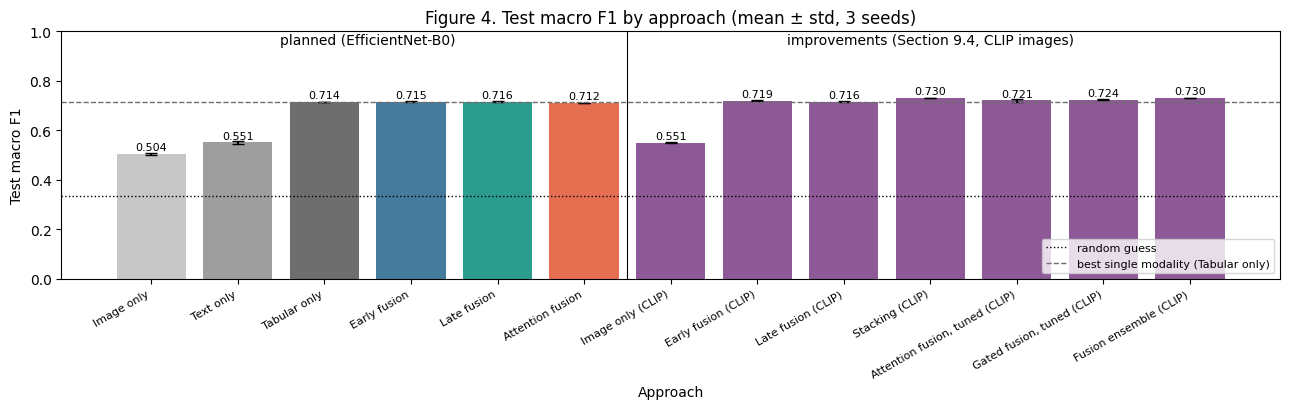

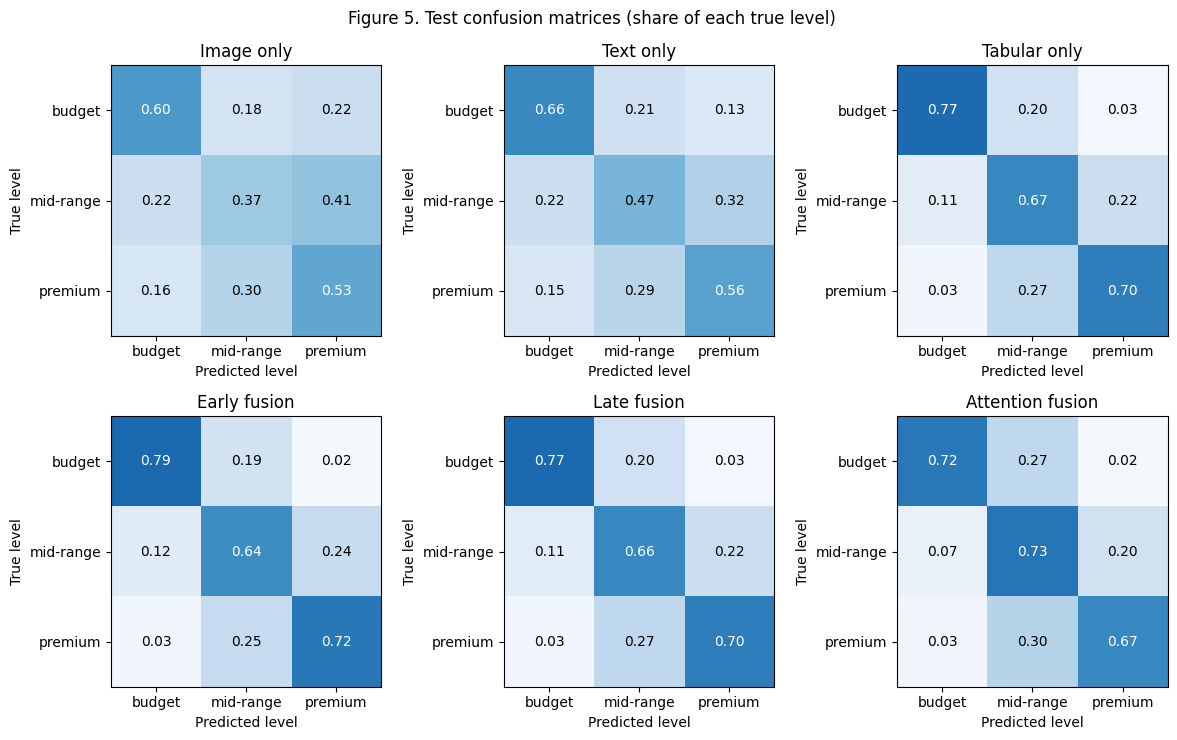

Table 12. Test F1 of each price level (first seed)


,F1 budget,F1 mid-range,F1 premium
Image only,0.588,0.404,0.500
Text only,0.635,0.478,0.560
Tabular only,0.798,0.631,0.718
Early fusion,0.802,0.622,0.729
Late fusion,0.798,0.630,0.721
Attention fusion,0.782,0.643,0.710


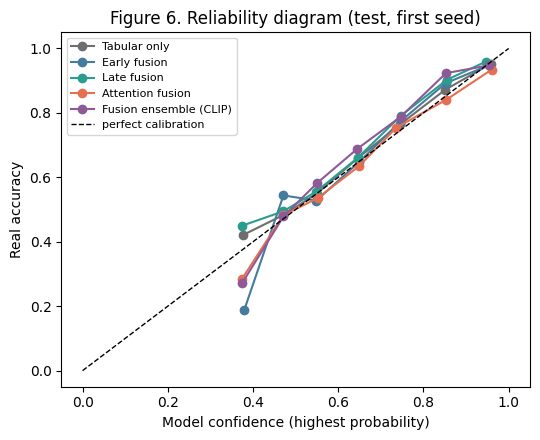

In [17]:
# Figure 4: test macro F1 of every model (mean and std over seeds)
SHOW = MAIN + IMPROVED
fig, ax = plt.subplots(figsize=(13, 4.2))
x = np.arange(len(SHOW))
means = [f1_runs[m].mean() for m in SHOW]
ax.bar(x, means, yerr=[f1_runs[m].std() for m in SHOW], capsize=4,
       color=[colour(m) for m in SHOW])
for xi, v in zip(x, means):
    ax.text(xi, v + 0.015, f"{v:.3f}", ha="center", fontsize=8)
ax.axhline(1 / 3, color="k", ls=":", lw=1, label="random guess")
ax.axhline(f1_runs[best_single].mean(), color="#6e6e6e", ls="--", lw=1,
           label=f"best single modality ({best_single})")
ax.axvline(len(MAIN) - 0.5, color="k", lw=0.8)
ax.text(len(MAIN) / 2 - 0.5, 0.95, "planned (EfficientNet-B0)", ha="center")
ax.text(len(MAIN) + len(IMPROVED) / 2 - 0.5, 0.95,
        f"improvements (Section 9.4, {IMG_NAME} images)", ha="center")
ax.set_xticks(x, SHOW, rotation=30, ha="right", fontsize=8)
ax.set_xlabel("Approach")
ax.set_ylabel("Test macro F1")
ax.set_ylim(0, 1)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Figure 4. Test macro F1 by approach (mean ± std, 3 seeds)")
plt.tight_layout()
save_fig(fig, "F04_model_comparison")

# Figure 5: confusion matrices, as a share of each true level (first seed)
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, m in zip(axes.ravel(), MAIN):
    cm = confusion_matrix(yt, PROBS[m][0]["test"].argmax(1),
                          normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(3), CLASSES)
    ax.set_yticks(range(3), CLASSES)
    ax.set_xlabel("Predicted level")
    ax.set_ylabel("True level")
    ax.set_title(m)
fig.suptitle("Figure 5. Test confusion matrices (share of each true level)")
plt.tight_layout()
save_fig(fig, "F05_confusion_matrices")

per_class = pd.DataFrame({
    m: f1_score(yt, PROBS[m][0]["test"].argmax(1), average=None)
    for m in MAIN}, index=[f"F1 {c}" for c in CLASSES]).T
print("Table 12. Test F1 of each price level (first seed)")
save_table(per_class.round(3), "T12_per_class_f1")

# Figure 6: reliability diagram (is the confidence honest?)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
bins = np.linspace(0, 1, 11)
for m in ["Tabular only", "Early fusion", "Late fusion", "Attention fusion",
          FINAL]:
    p = PROBS[m][0]["test"]
    conf, correct = p.max(1), p.argmax(1) == yt
    xs_, ys_ = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        inb = (conf > lo) & (conf <= hi)
        if inb.sum() >= 10:  # skip bins with very few listings
            xs_.append(conf[inb].mean())
            ys_.append(correct[inb].mean())
    ax.plot(xs_, ys_, "o-", color=colour(m), label=m)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.set_xlabel("Model confidence (highest probability)")
ax.set_ylabel("Real accuracy")
ax.legend(fontsize=8)
ax.set_title("Figure 6. Reliability diagram (test, first seed)")
plt.tight_layout()
save_fig(fig, "F06_reliability")

## 11. Overfitting

A model overfits when it learns the training data too well, including its noise, and then does worse on new data. I check this in three ways (Weeks 6 and 7 practicals):
1. The difference between the training score and the test score (Table 13). A big difference means overfitting.
2. The training and validation log loss of the tree models as more trees are added (Figure 7a).
3. The training and validation loss and macro F1 of the attention network after every epoch (Figure 7b and 7c).

Every model uses early stopping on the validation set. This means the version that is kept is the one from just before the validation loss starts to go up, which is the point where overfitting begins.

Table 13. Training vs held-out scores (mean over seeds)


,train macro F1,val macro F1,test macro F1,train minus test
Image only,0.644,0.508,0.504,0.140
Text only,0.753,0.556,0.551,0.202
Tabular only,0.785,0.702,0.714,0.071
Early fusion,0.861,0.699,0.715,0.145
Late fusion,0.789,0.703,0.716,0.072
Attention fusion,0.758,0.697,0.712,0.046


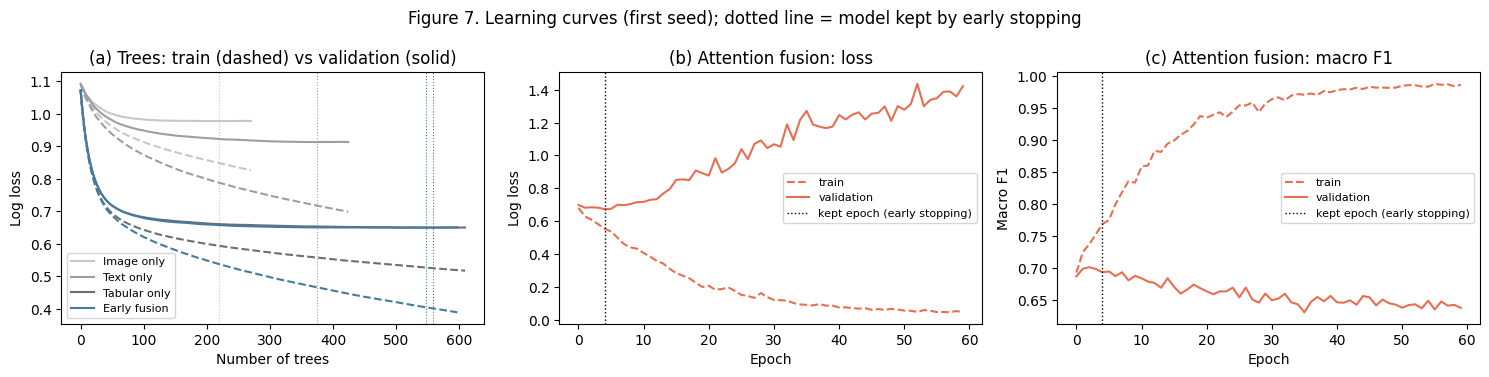

In [18]:
# Table 13: macro F1 on train, validation and test for each model
gap_rows = {}
for m in MAIN:
    # average over the 3 seeds for each set
    f1_of = {k: np.mean([f1_score(Y[k], r[k].argmax(1), average="macro")
                         for r in PROBS[m]]) for k in SPLIT}
    gap_rows[m] = {"train macro F1": f1_of["train"],
                   "val macro F1": f1_of["val"],
                   "test macro F1": f1_of["test"],
                   # a big gap here means overfitting
                   "train minus test": f1_of["train"] - f1_of["test"]}
print("Table 13. Training vs held-out scores (mean over seeds)")
save_table(pd.DataFrame(gap_rows).T.round(3), "T13_overfitting")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for m in ["Image only", "Text only", "Tabular only", "Early fusion"]:
    ev = TREES[m].evals_result()
    axes[0].plot(ev["validation_0"]["mlogloss"], ls="--",
                 color=MODEL_COLOURS[m])
    axes[0].plot(ev["validation_1"]["mlogloss"], color=MODEL_COLOURS[m],
                 label=m) # validation loss
    axes[0].axvline(TREES[m].best_iteration, color=MODEL_COLOURS[m],
                    lw=0.8, ls=":")
axes[0].set_xlabel("Number of trees")
axes[0].set_ylabel("Log loss")
axes[0].set_title("(a) Trees: train (dashed) vs validation (solid)")
axes[0].legend(fontsize=8)
h = ATT_HIST[0]
ep = np.arange(len(h["train loss"]))
att_colour = MODEL_COLOURS["Attention fusion"]
for ax, kind in zip(axes[1:], ["loss", "F1"]):
    ax.plot(ep, h[f"train {kind}"], "--", color=att_colour, label="train")
    ax.plot(ep, h[f"val {kind}"], color=att_colour, label="validation")
    ax.axvline(ATT_MODELS[0].best_epoch, color="k", ls=":", lw=1,
               label="kept epoch (early stopping)")
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
axes[1].set_ylabel("Log loss")
axes[1].set_title("(b) Attention fusion: loss")
axes[2].set_ylabel("Macro F1")
axes[2].set_title("(c) Attention fusion: macro F1")
fig.suptitle("Figure 7. Learning curves (first seed); dotted line = model "
             "kept by early stopping")
plt.tight_layout()
save_fig(fig, "F07_learning_curves")

## 12. Does the model use every modality?

A fusion model can quietly ignore one modality and depend almost only on another. This is called **modality dominance** or **collapse** (Week 7 lecture, Week 8 guest lecture). I check this in four ways, using the first-seed models on the test set:

1. **Missing modality:** I remove one modality and see how much macro F1 drops. Each model handles this in its own way. In late fusion, that modality's weight is set to 0. In attention fusion, its token is hidden from the attention. In early fusion, the features are replaced by their average from the training set, because a tree model cannot simply skip some of its inputs.
2. **Shuffled modality:** I give every listing the photo (or the text, or the details) of another random listing. If the score hardly drops, the model was not really using that modality (Week 7 lecture; Week 8 guest lecture).
3. **Noisy modality:** I add random (Gaussian) noise to the features of one modality, to see how well the model handles poor quality input (Week 7 lecture, Week 8 slides).
4. **What the attention model focuses on:** I look at how much attention the [CLS] token gives to each modality. I also measure **linear CKA** between each modality's encoder output and the final [CLS] vector. If a modality has a low CKA, it adds little to the final decision (Week 7 lecture).

Table 14. Test macro F1 when one modality is missing, shuffled or noisy


,nothing changed,image missing,image shuffled,image noise (std 0.5),image noise (std 1.0),text missing,text shuffled,text noise (std 0.5),text noise (std 1.0),tabular missing,tabular shuffled,tabular noise (std 0.5),tabular noise (std 1.0)
Early fusion,0.717,0.712,0.715,0.711,0.706,0.701,0.696,0.715,0.701,0.171,0.368,0.595,0.561
Late fusion,0.716,0.716,0.716,0.716,0.716,0.716,0.715,0.716,0.716,0.558,0.346,0.544,0.479
Attention fusion,0.712,0.712,0.694,0.712,0.706,0.706,0.687,0.714,0.705,0.569,0.397,0.665,0.571


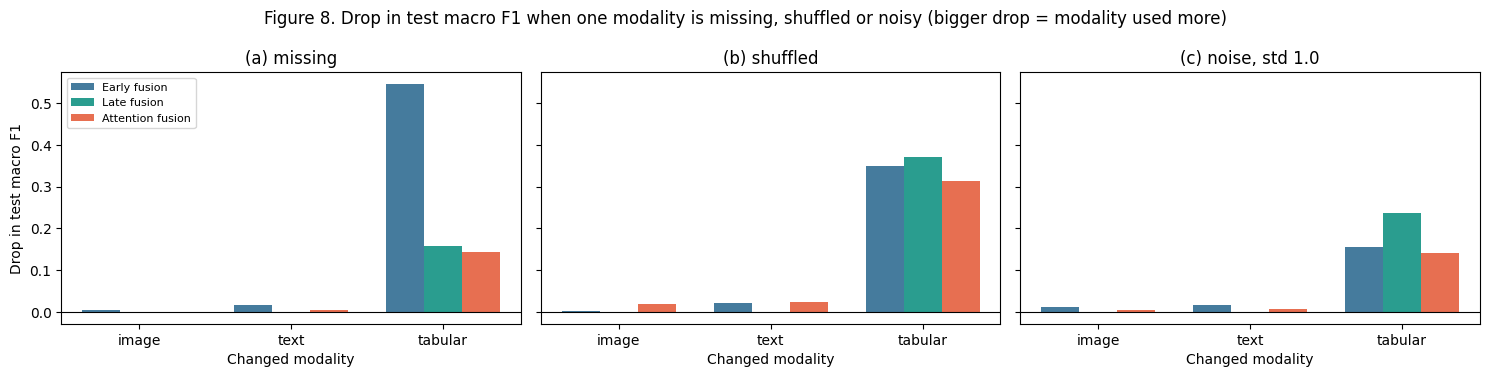

In [19]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(te))  # the same shuffle for every model
P_each0 = [PROBS[f"{m.capitalize()} only"][0]["test"] for m in MODS]
X_early = joined(BLOCKS)
cols = np.cumsum([0] + [BLOCKS[m].shape[1] for m in MODS])


def early_changed(j, how, level=0.0):
    """Early fusion test probabilities after changing block j."""
    Xc = X_early[te].copy()
    a, b = cols[j], cols[j + 1]
    if how == "missing":
        Xc[:, a:b] = X_early[tr, a:b].mean(0)
    elif how == "shuffle":
        Xc[:, a:b] = Xc[perm, a:b]
    else:  # noise, scaled to each column's training std
        sd = X_early[tr, a:b].std(0)
        Xc[:, a:b] += rng.normal(0, 1, Xc[:, a:b].shape) * sd * level
    p = TREES["Early fusion"].predict_proba(Xc).astype(np.float64)
    return p / p.sum(1, keepdims=True)


def late_changed(j, how, level=0.0):
    """Late fusion test probabilities after changing modality j."""
    if how == "missing":
        w = LATE_W[0].copy()
        w[j] = 0
        return combine(P_each0, w if w.sum() > 0 else np.ones(3))
    P = list(P_each0)
    mod = MODS[j]
    Xm = BLOCKS[mod][te].copy()
    if how == "shuffle":
        Xm = Xm[perm]
    else:
        Xm += rng.normal(0, 1, Xm.shape) * BLOCKS[mod][tr].std(0) * level
    p = TREES[f"{mod.capitalize()} only"].predict_proba(Xm)
    P[j] = p / p.sum(1, keepdims=True)
    return combine(P, LATE_W[0])


def att_changed(j, how, level=0.0):
    """Attention fusion test probabilities after changing modality j."""
    if how == "missing":
        return att_predict(ATT_MODELS[0], D_att, "test", hide=[j])[0]
    xs = [x.clone() for x in D_att["test"]["xs"]]
    if how == "shuffle":
        xs[j] = xs[j][torch.tensor(perm, device=DEVICE)]
    else:  # the inputs are standardised, so noise std = level
        xs[j] = xs[j] + torch.randn_like(xs[j]) * level
    return att_predict(ATT_MODELS[0], D_att, "test", xs=xs)[0]


def macro_f1(p):
    return f1_score(yt, p.argmax(1), average="macro")


changes = {"Early fusion": early_changed, "Late fusion": late_changed,
           "Attention fusion": att_changed}
tests = [("missing", 0.0), ("shuffled", 0.0)] + [
    ("noise", lv) for lv in CFG["noise_levels"]]
rob = {}
for m, fn in changes.items():
    row = {"nothing changed": macro_f1(PROBS[m][0]["test"])}
    for j, mod in enumerate(MODS):
        for how, lv in tests:
            label = f"{mod} {how}" + (f" (std {lv})" if how == "noise" else "")
            row[label] = macro_f1(fn(j, "shuffle" if how == "shuffled"
                                     else how, lv))
    rob[m] = row
rob = pd.DataFrame(rob).T
print("Table 14. Test macro F1 when one modality is missing, shuffled or "
      "noisy")
save_table(rob.round(3), "T14_robustness")

lv = CFG["noise_levels"][-1]
panels = [("missing", "(a) missing"), ("shuffled", "(b) shuffled"),
          (f"noise (std {lv})", f"(c) noise, std {lv}")]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (how, title) in zip(axes, panels):
    width = 0.25
    for k, m in enumerate(changes):
        drops = [rob.loc[m, "nothing changed"] - rob.loc[m, f"{mod} {how}"]
                 for mod in MODS]
        ax.bar(np.arange(3) + (k - 1) * width, drops, width,
               color=MODEL_COLOURS[m], label=m)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(3), MODS)
    ax.set_xlabel("Changed modality")
    ax.set_title(title)
axes[0].set_ylabel("Drop in test macro F1")
axes[0].legend(fontsize=8)
fig.suptitle("Figure 8. Drop in test macro F1 when one modality is "
             "missing, shuffled or noisy (bigger drop = modality used more)")
plt.tight_layout()
save_fig(fig, "F08_robustness")

Table 15. Attention fusion: share of attention per true level and CKA per modality (test)


,budget,mid-range,premium,CKA with fused [CLS]
image,0.220,0.243,0.226,0.163
text,0.183,0.195,0.195,0.337
tabular,0.598,0.562,0.580,0.822


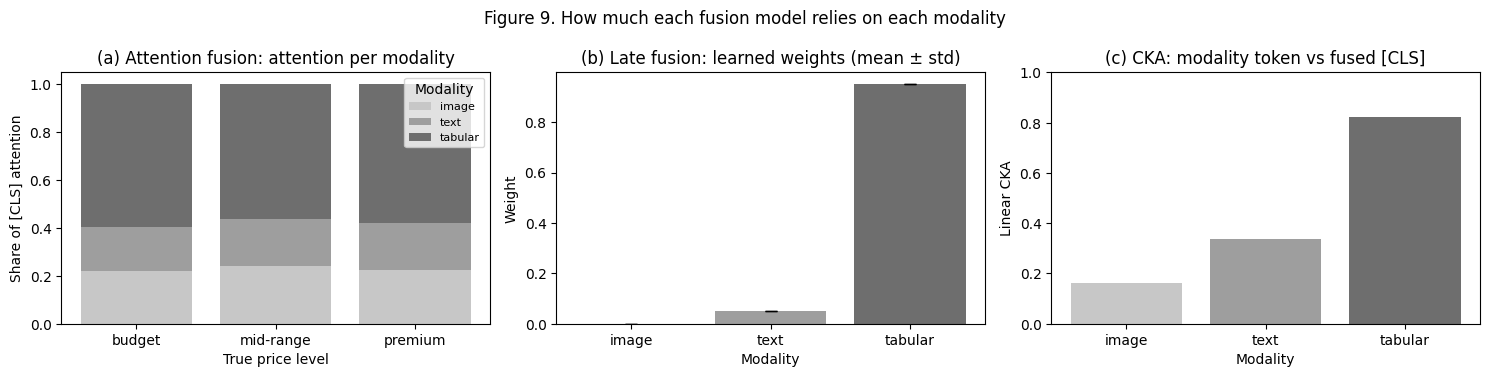

In [20]:
def linear_cka(X, Y_):
    """Linear centred kernel alignment between two representations.

    CKA = ||Y^T X||_F^2 / (||X^T X||_F ||Y^T Y||_F) after centring each
    column (Week 7 lecture). 1 = same information, 0 = unrelated.
    """
    X = X - X.mean(0)
    Y_ = Y_ - Y_.mean(0)
    return (np.linalg.norm(Y_.T @ X) ** 2
            / (np.linalg.norm(X.T @ X) * np.linalg.norm(Y_.T @ Y_)))


with torch.no_grad():
    ATT_MODELS[0].eval()
    d = D_att["test"]
    _, w_att, tokens, fused = ATT_MODELS[0](d["xs"], d["missing"],
                                            return_parts=True)
w_att, tokens, fused = (w_att.cpu().numpy(), tokens.cpu().numpy(),
                        fused.cpu().numpy())
cka = pd.Series({mod: linear_cka(tokens[:, j], fused)
                 for j, mod in enumerate(MODS)}, name="CKA with fused [CLS]")
# share of the [CLS] attention that goes to each modality token
w_share = w_att / w_att.sum(1, keepdims=True)
w_df = pd.DataFrame(w_share, columns=MODS)
w_df["true level"] = [CLASSES[c] for c in yt]
w_mean = w_df.groupby("true level")[MODS].mean().reindex(CLASSES)
print("Table 15. Attention fusion: share of attention per true level and "
      "CKA per modality (test)")
save_table(pd.concat([w_mean.T, cka], axis=1).round(3), "T15_attention_cka")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
bottom = np.zeros(3)
greys = ["#c7c7c7", "#9e9e9e", "#6e6e6e"]
for mod, col in zip(MODS, greys):
    axes[0].bar(CLASSES, w_mean[mod], bottom=bottom, color=col, label=mod)
    bottom += w_mean[mod].values
axes[0].set_ylabel("Share of [CLS] attention")
axes[0].set_xlabel("True price level")
axes[0].set_title("(a) Attention fusion: attention per modality")
axes[0].legend(title="Modality", fontsize=8)
axes[1].bar(MODS, late_w.mean().values, yerr=late_w.std().values, capsize=4,
            color=greys)
axes[1].set_ylabel("Weight")
axes[1].set_xlabel("Modality")
axes[1].set_title("(b) Late fusion: learned weights (mean ± std)")
axes[2].bar(MODS, cka.values, color=greys)
axes[2].set_ylim(0, 1)
axes[2].set_ylabel("Linear CKA")
axes[2].set_xlabel("Modality")
axes[2].set_title("(c) CKA: modality token vs fused [CLS]")
fig.suptitle("Figure 9. How much each fusion model relies on each modality")
plt.tight_layout()
save_fig(fig, "F09_modality_reliance")

## 13. Bias and fairness

The Week 7 lecture names three places where bias can come from: the **data**, the **labels** and the **model**. It also warns that fusion can **amplify** bias, especially for **intersectional** groups (people or items that belong to two groups at once).

In this project, the share of premium listings is very different between areas, from about 20% to about 60%. So a model might learn "expensive suburb = premium" instead of looking at what the place actually offers. The labels can also be biased, because prices are set by hosts, so they reflect the hosts' and the market's choices and not a fair "true" value. This is similar to the annotators' assumptions in the Week 9 practical.

I check this in five ways:
1. **By area:** the test macro F1 of the final model in each area, and the predicted share of premium listings compared with the true share (Figure 10).
2. **Fairness metrics by group** (Week 7 lecture). For each group I measure three things: the share predicted as premium (**demographic parity**), how many real premium listings are found (**true positive rate**), and how many other listings are wrongly called premium (**false positive rate**). The groups are: area price group (areas split into three equal groups by their share of premium listings in the training set), room type, and the **intersectional** group of area price group × room type. I compare the best single-modality model with each fusion model and the final model, to see if fusion makes the gaps bigger.
3. **With and without area:** every fusion model is trained again without the area columns.
4. **Within the same area** (like the "same speaker" check in the Week 8 practical): can the model still tell budget from premium listings **inside one area**? If yes, it is using the listing itself and not only its location.
5. **Listings with no reviews yet:** these are usually new hosts, the group this project wants to help most.

Table 16. Fusion ensemble (CLIP) by area (areas with 30+ test listings)


,test listings,true premium share,predicted premium share,accuracy,macro F1
area,,,,,
Maribyrnong,73,0.192,0.260,0.877,0.802
Moreland,103,0.233,0.243,0.835,0.811
Wyndham,92,0.261,0.413,0.739,0.657
Hobsons Bay,38,0.263,0.263,0.789,0.697
Whitehorse,66,0.288,0.288,0.682,0.648
Darebin,51,0.294,0.255,0.725,0.623
Hume,44,0.295,0.341,0.795,0.737
Glen Eira,57,0.316,0.263,0.754,0.749
Brimbank,34,0.324,0.265,0.618,0.558


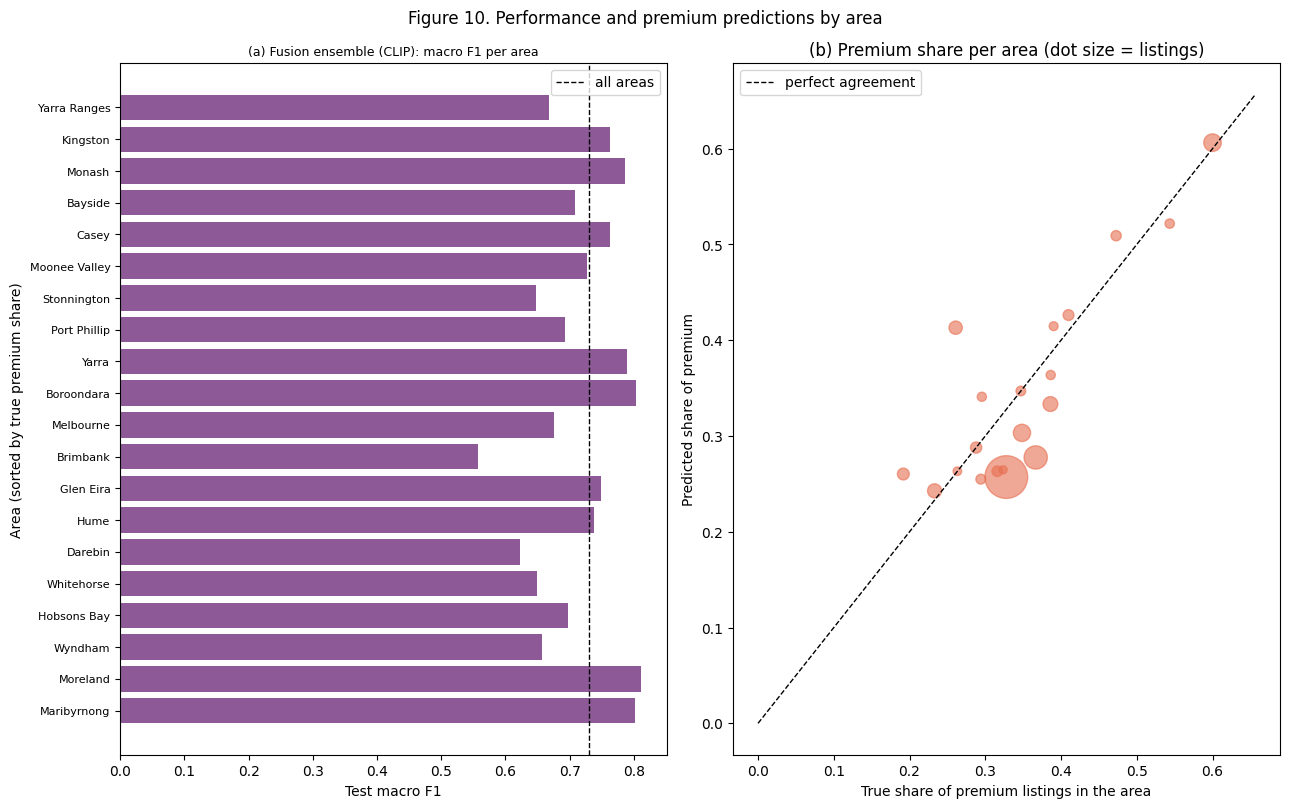

In [21]:
# Check the final model area by area (first seed, test set)
p_best = PROBS[FINAL][0]["test"]
pred_best = p_best.argmax(1)
area_te = area.values[te]
rows = []
for a in pd.unique(area_te):
    m_ = area_te == a
    if m_.sum() < MIN_GROUP:
        continue # skip areas with too few test listings to be reliable
    rows.append({"area": a, "test listings": int(m_.sum()),
                 "true premium share": np.mean(yt[m_] == 2),
                 "predicted premium share": np.mean(pred_best[m_] == 2),
                 "accuracy": accuracy_score(yt[m_], pred_best[m_]),
                 "macro F1": f1_score(yt[m_], pred_best[m_],
                                      average="macro")})
by_area = pd.DataFrame(rows).set_index("area").sort_values(
    "true premium share")
print(f"Table 16. {FINAL} by area (areas with {MIN_GROUP}+ test "
      "listings)")
save_table(by_area.round(3), "T16_by_area")

fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * len(by_area) + 1.8))
# (a) Macro F1 in each area, with the overall score as a dashed line
yy = np.arange(len(by_area))
axes[0].barh(yy, by_area["macro F1"], color=colour(FINAL))
axes[0].axvline(f1_score(yt, pred_best, average="macro"), color="k",
                ls="--", lw=1, label="all areas")
axes[0].set_yticks(yy, by_area.index, fontsize=8)
axes[0].set_xlabel("Test macro F1")
axes[0].set_ylabel("Area (sorted by true premium share)")
axes[0].set_title(f"(a) {FINAL}: macro F1 per area", fontsize=9)
axes[0].legend()
# (b) True vs predicted premium share per area; dots above the line
# mean the model calls too many listings premium in that area
axes[1].scatter(by_area["true premium share"],
                by_area["predicted premium share"],
                s=by_area["test listings"], alpha=0.6, color="#e76f51")
lim = [0, by_area[["true premium share",
                   "predicted premium share"]].values.max() + 0.05]
axes[1].plot(lim, lim, "k--", lw=1, label="perfect agreement")
axes[1].set_xlabel("True share of premium listings in the area")
axes[1].set_ylabel("Predicted share of premium")
axes[1].set_title("(b) Premium share per area (dot size = listings)")
axes[1].legend()
fig.suptitle("Figure 10. Performance and premium predictions by area")
plt.tight_layout()
save_fig(fig, "F10_bias_by_area")

Table 17. Fairness metrics for 'premium' by group (test, first seed)


test listings  \
grouping                     group                                model                                   
area price group             middle-price areas                   Tabular only                     1451   
                             high-price areas                     Tabular only                      849   
                             low-price areas                      Tabular only                      432   
room type                    Private room                         Tabular only                      554   
                             Entire home/apt                      Tabular only                     2161   
area price group x room type middle-price areas | Private room    Tabular only                      271   
                             high-price areas | Private room      Tabular only                      133   
                             middle-price areas | Entire home/apt Tabular only                     1172   
                             high-price areas | Entire home/apt   Tabular only                      710   
                             low-price areas | Private room       Tabular only                      150   
                             low-price areas | Entire home/apt    Tabular only                      279   
area price group             middle-price areas                   Early fusion                     1451   
                             high-price areas                     Early fusion                      849   
                             low-price areas                      Early fusion                      432   
room type                    Private room                         Early fusion                      554   
                             Entire home/apt                      Early fusion                     2161   
area price group x room type middle-price areas | Private room    Early fusion                      271   
                             high-price areas | Private room      Early fusion                      133   
                             middle-price areas | Entire home/apt Early fusion                     1172   
                             high-price areas | Entire home/apt   Early fusion                      710   
                             low-price areas | Private room       Early fusion                      150   
                             low-price areas | Entire home/apt    Early fusion                      279   
area price group             middle-price areas                   Late fusion                      1451   
                             high-price areas                     Late fusion                       849   
                             low-price areas                      Late fusion                       432   
room type                    Private room                         Late fusion                       554   
                             Entire home/apt                      Late fusion                      2161   
area price group x room type middle-price areas | Private room    Late fusion                       271   
                             high-price areas | Private room      Late fusion                       133   
                             middle-price areas | Entire home/apt Late fusion                      1172   
                             high-price areas | Entire home/apt   Late fusion                       710   
                             low-price areas | Private room       Late fusion                       150   
                             low-price areas | Entire home/apt    Late fusion                       279   
area price group             middle-price areas                   Attention fusion                 1451   
                             high-price areas                     Attention fusion                  849   
                             low-price areas                      Attention fusion                  432   
room type               

Table 18. Fairness gaps across groups (largest minus smallest). A demographic parity gap much bigger than the true premium share gap means the model exaggerates the group differences.


demographic parity gap  \
grouping                     model                                            
area price group             Attention fusion                         0.102   
                             Early fusion                             0.118   
                             Fusion ensemble (CLIP)                   0.122   
                             Late fusion                              0.161   
                             Tabular only                             0.161   
area price group x room type Attention fusion                         0.435   
                             Early fusion                             0.475   
                             Fusion ensemble (CLIP)                   0.461   
                             Late fusion                              0.486   
                             Tabular only                             0.485   
room type                    Attention fusion                         0.351   
                             Early fusion                             0.387   
                             Fusion ensemble (CLIP)                   0.374   
                             Late fusion                              0.379   
                             Tabular only                             0.375   

                                                     true premium share gap  \
grouping                     model                                            
area price group             Attention fusion                         0.173   
                             Early fusion                             0.173   
                             Fusion ensemble (CLIP)                   0.173   
                             Late fusion                              0.173   
                             Tabular only                             0.173   
area price group x room type Attention fusion                         0.467   
                             Early fusion                             0.467   
                             Fusion ensemble (CLIP)                   0.467   
                             Late fusion                              0.467   
                             Tabular only                             0.467   
room type                    Attention fusion                         0.354   
                             Early fusion                             0.354   
                             Fusion ensemble (CLIP)                   0.354   
                             Late fusion                              0.354   
                             Tabular only                             0.354   

                                                     TPR gap  FPR gap  \
grouping                     model                                      
area price group             Attention fusion          0.115    0.024   
                             Early fusion              0.119    0.016   
                             Fusion ensemble (CLIP)    0.118    0.016   
                             Late fusion               0.130    0.076   
                             Tabular only              0.138    0.076   
area price group x room type Attention fusion          0.455    0.220   
                             Early fusion              0.494    0.233   
                             Fusion ensemble (CLIP)    0.478    0.214   
                             Late fusion               0.492    0.207   
                             Tabular only              0.492    0.205   
room type                    Attention fusion          0.349    0.152   
                             Early fusion              0.402    0.179   
                             Fusion ensemble (CLIP)    0.420    0.158   
                             Late fusion               0.442    0.170   
                             Tabular only              0.437    0.167   

                                                     accuracy gap  
grouping                     model                     

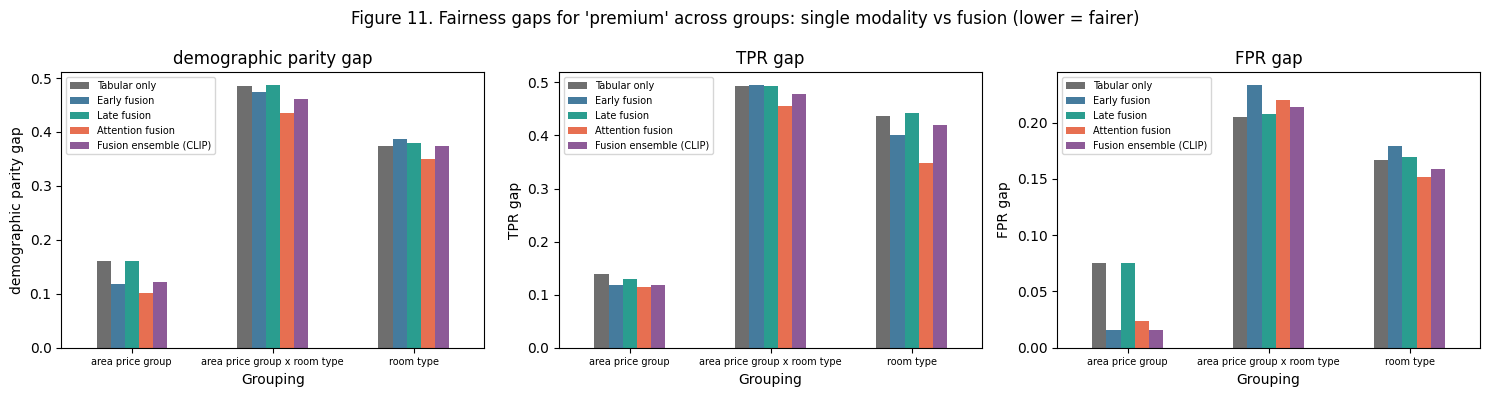

In [22]:
# Area price group: areas split into three equal groups by their share of
# premium listings in the TRAINING set
train_share = pd.Series(y_all[tr] == 2).groupby(area.values[tr]).mean()
area_group_of = pd.qcut(train_share.rank(method="first"), 3,
                        labels=["low-price areas", "middle-price areas",
                                "high-price areas"])
area_group = area.map(area_group_of).astype(str).values
room_te = df["room_type"].values[te].astype(str)
GROUPINGS = {
    "area price group": area_group[te],
    "room type": room_te,
    "area price group x room type": np.array(
        [f"{a} | {r}" for a, r in zip(area_group[te], room_te)]),
}


def fairness_rows(model):
    """Demographic parity, TPR and FPR for 'premium' in every group."""
    pred = PROBS[model][0]["test"].argmax(1)
    out = []
    for grouping, labels in GROUPINGS.items():
        for gname in pd.unique(labels):
            m_ = labels == gname
            pos, neg = m_ & (yt == 2), m_ & (yt != 2)
            if m_.sum() < MIN_GROUP:
                continue
            # TPR and FPR need enough real premium (or other) listings in
            # the group; with fewer than 5 they are left empty (NaN)
            out.append({"model": model, "grouping": grouping,
                        "group": gname, "test listings": int(m_.sum()),
                        "true premium share": np.mean(yt[m_] == 2),
                        "predicted premium share": np.mean(pred[m_] == 2),
                        "TPR premium": np.mean(pred[pos] == 2)
                        if pos.sum() >= 5 else np.nan,
                        "FPR premium": np.mean(pred[neg] == 2)
                        if neg.sum() >= 5 else np.nan,
                        "accuracy": accuracy_score(yt[m_], pred[m_])})
    return out


FAIR_MODELS = [best_single] + MAIN[3:] + [FINAL]
fair = pd.DataFrame(sum([fairness_rows(m) for m in FAIR_MODELS], []))
print("Table 17. Fairness metrics for 'premium' by group (test, first seed)")
save_table(fair.set_index(["grouping", "group", "model"]).round(3),
           "T17_fairness_by_group")


def spread(s):
    """Largest minus smallest value across groups (empty values skipped)."""
    s = s.dropna()
    return s.max() - s.min() if len(s) > 1 else np.nan


gaps = fair.groupby(["grouping", "model"]).agg(
    **{"demographic parity gap": ("predicted premium share", spread),
       "true premium share gap": ("true premium share", spread),
       "TPR gap": ("TPR premium", spread),
       "FPR gap": ("FPR premium", spread),
       "accuracy gap": ("accuracy", spread)})
print("Table 18. Fairness gaps across groups (largest minus smallest). "
      "A demographic parity gap much bigger than the true premium share "
      "gap means the model exaggerates the group differences.")
save_table(gaps.round(3), "T18_fairness_gaps")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["demographic parity gap", "TPR gap",
                             "FPR gap"]):
    gp = gaps[metric].unstack("model")
    gp = gp[[m for m in FAIR_MODELS if m in gp.columns]]
    gp.plot.bar(ax=ax, color=[colour(m) for m in gp.columns], rot=0)
    ax.set_xlabel("Grouping")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.tick_params(axis="x", labelsize=7)
    ax.legend(fontsize=7)
fig.suptitle("Figure 11. Fairness gaps for 'premium' across groups: "
             "single modality vs fusion (lower = fairer)")
plt.tight_layout()
save_fig(fig, "F11_fairness_gaps")

In [23]:
# Fusion models without the area columns (same settings and seeds)
B_noarea = tree_blocks(tr, N_PCA, with_area=False)
P_noarea, _, _, _ = run_trees(B_noarea)
for m in ["Tabular only", "Early fusion", "Late fusion"]:
    PROBS[f"{m} (no area)"] = P_noarea[m]
D_noarea = nn_inputs(with_area=False)
for s in SEEDS:
    m, _ = train_attention(D_noarea, seed=s, **ATT_PARAMS)
    PROBS.setdefault("Attention fusion (no area)", []).append(
        {k: att_predict(m, D_noarea, k)[0] for k in SPLIT})


def within_area_auc(p):
    """Inside each area: the chance that a premium listing gets a higher
    premium probability than a budget listing (0.5 = cannot tell)."""
    out, weights = [], []
    for a in pd.unique(area_te):
        m_ = (area_te == a) & (yt != 1)
        if (yt[m_] == 2).sum() >= 3 and (yt[m_] == 0).sum() >= 3:
            out.append(roc_auc_score(yt[m_] == 2, p[m_, 2]))
            weights.append(m_.sum())
    return np.average(out, weights=weights) if out else np.nan


def worst_area_f1(p):
    """Lowest macro F1 over the areas in Table 16."""
    return min(f1_score(yt[area_te == a], p.argmax(1)[area_te == a],
                        average="macro") for a in by_area.index)


area_rows = {}
for m in ["Tabular only", "Early fusion", "Late fusion", "Attention fusion"]:
    for v in [m, f"{m} (no area)"]:
        runs = [r["test"] for r in PROBS[v]]
        area_rows[v] = {
            "test macro F1": np.mean([macro_f1(p) for p in runs]),
            "worst area macro F1": np.mean([worst_area_f1(p) for p in runs]),
            "within-area AUC (premium vs budget)": np.mean(
                [within_area_auc(p) for p in runs])}
area_rows[f"{FINAL} (final model)"] = {
    "test macro F1": np.mean([macro_f1(r["test"]) for r in PROBS[FINAL]]),
    "worst area macro F1": np.mean([worst_area_f1(r["test"])
                                    for r in PROBS[FINAL]]),
    "within-area AUC (premium vs budget)": np.mean(
        [within_area_auc(r["test"]) for r in PROBS[FINAL]])}
# A model that only knows the area: predict the area's most common class
area_mode = pd.Series(y_all[tr]).groupby(area.values[tr]).agg(
    lambda s: s.value_counts().idxmax())
area_only = area.map(area_mode).fillna(1).astype(int).values[te]
area_rows["Area only (most common class of the area)"] = {
    "test macro F1": f1_score(yt, area_only, average="macro"),
    "worst area macro F1": np.nan,
    "within-area AUC (premium vs budget)": 0.5}
print("Table 19. With and without the area columns (mean over seeds)")
save_table(pd.DataFrame(area_rows).T.round(3), "T19_area_effect")

# Listings with no reviews yet (often new hosts)
nr = tab["no_reviews_yet"].values[te] == 1
new_hosts = pd.DataFrame({
    m: {"macro F1, has reviews": f1_score(
        yt[~nr], PROBS[m][0]["test"].argmax(1)[~nr], average="macro"),
        "macro F1, no reviews yet": f1_score(
            yt[nr], PROBS[m][0]["test"].argmax(1)[nr], average="macro"),
        "test listings with no reviews": int(nr.sum())}
    for m in MAIN + [FINAL]}).T
print("Table 20. Listings with and without reviews (test, first seed)")
save_table(new_hosts.round(3), "T20_no_reviews")

Table 19. With and without the area columns (mean over seeds)


,test macro F1,worst area macro F1,within-area AUC (premium vs budget)
Tabular only,0.714,0.590,0.964
Tabular only (no area),0.699,0.519,0.966
Early fusion,0.715,0.583,0.969
Early fusion (no area),0.711,0.593,0.970
Late fusion,0.716,0.581,0.966
Late fusion (no area),0.699,0.526,0.967
Attention fusion,0.712,0.552,0.966
Attention fusion (no area),0.701,0.560,0.964
Fusion ensemble (CLIP) (final model),0.730,0.567,0.973
Area only (most common class of the area),0.422,NaN,0.500


Table 20. Listings with and without reviews (test, first seed)


,"macro F1, has reviews","macro F1, no reviews yet",test listings with no reviews
Image only,0.495,0.495,409.0
Text only,0.559,0.519,409.0
Tabular only,0.718,0.691,409.0
Early fusion,0.721,0.680,409.0
Late fusion,0.718,0.696,409.0
Attention fusion,0.719,0.656,409.0
Fusion ensemble (CLIP),0.734,0.693,409.0


## 14. Generalisation to unseen areas

In the Week 8 practical we asked what happens with a speaker the model has never heard during training, and we tested it by keeping some speakers out of training. In my project the same question is: **does the model still work in an area it has never seen?** This matters if the model is used later in a new suburb or a new city (generalisation and scalability).

To test this, I keep about 20% of the areas completely out of training and use them as the test set. The model is trained on the other areas, with its own validation set, and I repeat this 3 times with a different set of areas each time. The area columns are not used here, because a new area would not have its own column. I compare the single-modality models with early and late fusion, using the same tree settings as before.

In [24]:
area_names = np.array(sorted(area.unique()))
holdout_rows = []
for rep in range(CFG["n_area_holdouts"]):
    r = np.random.default_rng(SEED + rep)
    n_hold = max(1, int(len(area_names) * CFG["area_holdout_share"]))
    held = r.choice(area_names, n_hold, replace=False)
    is_test = area.isin(held).values
    # validation: 15% of the remaining groups; the rest is training
    rest_groups = np.unique(groups[~is_test])
    val_groups = r.choice(rest_groups, int(0.15 * len(rest_groups)),
                          replace=False)
    is_val = np.isin(groups, val_groups) & ~is_test
    S_area = {"train": np.where(~is_test & ~is_val)[0],
              "val": np.where(is_val)[0], "test": np.where(is_test)[0]}
    B_area = tree_blocks(S_area["train"], N_PCA, with_area=False,
                         tag=f"areas_{rep}")
    P_area, _, _, _ = run_trees(B_area, S_area, seeds=[SEED])
    y_area = y_all[S_area["test"]]
    for m in MAIN[:5]:
        holdout_rows.append({
            "repeat": rep, "model": m, "held-out areas": n_hold,
            "test listings": len(y_area),
            "macro F1, unseen areas": f1_score(
                y_area, P_area[m][0]["test"].argmax(1), average="macro")})
holdout = pd.DataFrame(holdout_rows)
holdout_summary = holdout.groupby("model")["macro F1, unseen areas"].agg(
    ["mean", "std"]).reindex(MAIN[:5])
holdout_summary.columns = ["macro F1, unseen areas (mean)", "std"]
holdout_summary["macro F1, normal test set, no area"] = [
    np.mean([macro_f1(r["test"]) for r in PROBS[
        f"{m} (no area)" if f"{m} (no area)" in PROBS else m]])
    for m in holdout_summary.index]
print("Table 21. Unseen areas: macro F1 when whole areas are held out "
      "(3 repeats)")
save_table(holdout_summary.round(3), "T21_unseen_areas")

Table 21. Unseen areas: macro F1 when whole areas are held out (3 repeats)


,"macro F1, unseen areas (mean)",std,"macro F1, normal test set, no area"
model,,,
Image only,0.469,0.026,0.504
Text only,0.514,0.024,0.551
Tabular only,0.677,0.027,0.699
Early fusion,0.682,0.028,0.711
Late fusion,0.678,0.025,0.699


## 15. Failure cases

Here I look at the worst mistakes of the final model: the **severe** mistakes it made with the most confidence, where a budget listing is predicted as premium or a premium listing as budget. Looking at real examples helps to understand why the model gets them wrong.

To protect privacy, I only show the cleaned title (first 80 characters) and a few listing details. No photos and no host information are shown.

I also check if mistakes happen more often in three situations: when the photo is missing, when the text is very short, and when the price is close to the edge between two price levels.

In [25]:
# Table 22: the 10 severe mistakes the final model was most sure about
conf = p_best.max(1) # how confident the model is in its prediction
severe = np.where(np.abs(pred_best - yt) == 2)[0]   # budget <-> premium
top = severe[np.argsort(-conf[severe])][:10]
fail = pd.DataFrame({
    # only the cleaned title and a few details, for privacy
    "title": df["name"].fillna("").map(clean_text).str[:80].values[te][top],
    "room type": df["room_type"].values[te][top],
    "guests": df["accommodates"].values[te][top],
    "price $": df["price_num"].values[te][top].round(0),
    "true": [CLASSES[c] for c in yt[top]],
    "predicted": [CLASSES[c] for c in pred_best[top]],
    "confidence": conf[top].round(2),
})
print(f"Table 22. Most confident severe mistakes of {FINAL}")
save_table(fail, "T22_failure_cases")
# Table 23: is the error rate higher in some situations?
wrong = pred_best != yt
words_te = n_words.values[te]
price_te = df["price_num"].values[te]
# within 10% of the $ edge between budget/mid-range or mid-range/premium
near_edge = np.min(np.abs(price_te[:, None] - edges[1:3][None, :])
                   / edges[1:3][None, :], axis=1) < 0.10
err = pd.Series({
    "error rate, all test listings": wrong.mean(),
    "error rate, photo missing": wrong[~img_ok[te]].mean()
    if (~img_ok[te]).any() else np.nan,
    "error rate, text under 20 words": wrong[words_te < 20].mean()
    if (words_te < 20).any() else np.nan,
    "error rate, price within 10% of a class edge": wrong[near_edge].mean(),
    "error rate, price far from the edges": wrong[~near_edge].mean(),
}, name=FINAL).to_frame()
print("Table 23. When does the final model make mistakes?")
save_table(err.round(3), "T23_error_rates")

Table 22. Most confident severe mistakes of Fusion ensemble (CLIP)


,title,room type,guests,price $,true,predicted,confidence
0,Furnished room between airport and cbd,Private room,1,588.0,premium,budget,0.99
1,Sublet,Private room,1,339.0,premium,budget,0.98
2,Beautiful double bed room,Private room,1,424.0,premium,budget,0.98
3,Southbank scenic 1 bed ensuite,Private room,1,378.0,premium,budget,0.96
4,"Friends, food and living in North Melbourne",Shared room,1,799.0,premium,budget,0.96
5,Serene waterside stay,Private room,2,332.0,premium,budget,0.94
6,"QUIET, NICE AND EASY TO ACCESS",Private room,1,380.0,premium,budget,0.93
7,Welcome to our comfortable and relaxing home!,Private room,2,840.0,premium,budget,0.92
8,Escape to Nature,Private room,3,650.0,premium,budget,0.79
9,"Near shops, free Wi-Fi, Netflix",Private room,3,346.0,premium,budget,0.78


Table 23. When does the final model make mistakes?


,Fusion ensemble (CLIP)
"error rate, all test listings",0.275
"error rate, photo missing",0.346
"error rate, text under 20 words",0.186
"error rate, price within 10% of a class edge",0.422
"error rate, price far from the edges",0.224


## 16. Efficiency

A good model also has to be practical to use. Following the Week 7 practical, I report what each model **costs**: how big it is, how long it takes to train, and how long it takes to predict one listing. I also show what this means for **10,000** new listings.

Before any model can predict, a new listing has to be turned into features: its photo is downloaded and passed through EfficientNet-B0 and CLIP, and its text through BERT. This step is the same for every model, so it is reported separately. All times are measured on the same free Colab GPU used for the rest of the notebook.

In [26]:
def median_time(fn, repeats=5):
    """Median time of a few runs, so one slow run does not count."""
    ts = []
    for _ in range(repeats):
        t0 = time.time()
        fn()
        ts.append(time.time() - t0)
    return float(np.median(ts))

# How each model predicts the whole test set
predict_fn = {
    "Image only": lambda: TREES["Image only"].predict_proba(
        BLOCKS["image"][te]),
    "Text only": lambda: TREES["Text only"].predict_proba(BLOCKS["text"][te]),
    "Tabular only": lambda: TREES["Tabular only"].predict_proba(
        BLOCKS["tabular"][te]),
    "Early fusion": lambda: TREES["Early fusion"].predict_proba(X_early[te]),
    # late fusion has to run all three single-modality models
    "Late fusion": lambda: [TREES[f"{m.capitalize()} only"].predict_proba(
        BLOCKS[m][te]) for m in MODS],
    "Attention fusion": lambda: att_predict(ATT_MODELS[0], D_att, "test"),
}
# Table 24: size, training time and prediction time of each model
eff_rows = {}
for m in MAIN:
    ms_per_listing = 1000 * median_time(predict_fn[m]) / len(te)
    # size: weights for the network, number of trees for XGBoost
    size = (f"{N_PARAMS:,} weights" if m == "Attention fusion" else
            f"{TREES[m].best_iteration + 1} trees" if m in TREES else
            "3 tree models")
    eff_rows[m] = {"size": size,
                   "training time (s, mean)": round(np.mean(TRAIN_TIME[m]),
                                                    2),
                   "prediction time per listing (ms)": round(ms_per_listing,
                                                             4),
                   "prediction time for 10,000 listings (s)": round(
                       ms_per_listing * 10_000 / 1000, 3)}
efficiency = pd.DataFrame(eff_rows).T
print("Table 24. Efficiency of each model (Week 7 practical)")
save_table(efficiency, "T24_efficiency")
# Table 25: time to turn new listings into features (photo, CLIP, BERT)
feature_cost = pd.Series({
    "photo download + EfficientNet + CLIP per listing (ms)": 1000 * TIMES[
        "photo download and image features (s)"] / len(df),
    "BERT per listing (ms)": 1000 * TIMES["text features (s)"] / len(df),
    "features for 10,000 new listings (minutes)": (
        TIMES["photo download and image features (s)"]
        + TIMES["text features (s)"]) / len(df) * 10_000 / 60,
}, name="value").to_frame()
print("Table 25. Cost of turning new listings into features (the same for "
      "every model; close to 0 if the features were loaded from Drive)")
save_table(feature_cost.round(2), "T25_feature_cost")

Table 24. Efficiency of each model (Week 7 practical)


,size,"training time (s, mean)",prediction time per listing (ms),"prediction time for 10,000 listings (s)"
Image only,221 trees,1.21,0.0022,0.022
Text only,375 trees,2.14,0.0032,0.032
Tabular only,560 trees,2.62,0.0051,0.051
Early fusion,548 trees,3.14,0.0073,0.073
Late fusion,3 tree models,5.97,0.0088,0.088
Attention fusion,"537,347 weights",27.62,0.0012,0.012


Table 25. Cost of turning new listings into features (the same for every model; close to 0 if the features were loaded from Drive)


,value
photo download + EfficientNet + CLIP per listing (ms),1.21
BERT per listing (ms),0.49
"features for 10,000 new listings (minutes)",0.28


## 17. Save results and summary

All the tables (CSV files) and figures (PNG files) are saved in the output folder, and these are the same ones used in the report. I also save the test predictions of every model, so anyone can check the evaluation again without training all the models from the start.

The summary below lists the main results and checks the success criterion from the proposal.

In [27]:
# Save the test predictions of every model (first seed)
np.savez_compressed(
    OUT / "test_probabilities.npz", y_test=yt,
    **{k.replace(" ", "_"): v[0]["test"] for k, v in PROBS.items()})
# Save how long each step took
pd.Series({k: round(v, 1) for k, v in TIMES.items()}).to_csv(
    TAB_DIR / "T26_times.csv")
print("Saved tables:", sorted(p.name for p in TAB_DIR.glob("*.csv")))
print("Saved figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))
print()
# Summary: check the success criterion for the planned and final models
print(f"Best single modality: {best_single} "
      f"(test macro F1 {f1_runs[best_single].mean():.3f})")
for label, m in [("Best planned fusion model", best_fusion),
                 ("Final model (chosen on validation)", FINAL)]:
    # met = the gain is positive and bigger than 2 x the seed std
    ok = bool(seed_gap.loc[m, "difference larger than 2 x seed std?"])
    gain = seed_gap.loc[m, f"gain over {best_single}"]
    print(f"{label}: {m}, test macro F1 {f1_runs[m].mean():.3f} "
          f"(gain {gain:+.3f}); success criterion (gain larger than the "
          f"seed variation): {'met' if ok and gain > 0 else 'not met'}")
# Final table with the main metrics of all models
display(test_table.loc[MAIN + IMPROVED, ["accuracy", "macro F1",
                                         "macro ROC AUC", "ECE",
                                         "severe error rate"]])

Saved tables: ['T01_data_summary.csv', 'T02_missing_values.csv', 'T03_text_quality.csv', 'T04_split.csv', 'T05_image_quality.csv', 'T06_feature_extractors.csv', 'T07_xgb_sweep.csv', 'T08_late_fusion_rules.csv', 'T09_attention_sweep.csv', 'T09b_improved_neural_sweep.csv', 'T09c_final_model_selection.csv', 'T10_test_results.csv', 'T11_seed_gap.csv', 'T12_per_class_f1.csv', 'T13_overfitting.csv', 'T14_robustness.csv', 'T15_attention_cka.csv', 'T16_by_area.csv', 'T17_fairness_by_group.csv', 'T18_fairness_gaps.csv', 'T19_area_effect.csv', 'T20_no_reviews.csv', 'T21_unseen_areas.csv', 'T22_failure_cases.csv', 'T23_error_rates.csv', 'T24_efficiency.csv', 'T25_feature_cost.csv', 'T26_times.csv']
Saved figures: ['F01_price_levels.png', 'F02_description_length.png', 'F03_image_quality.png', 'F04_model_comparison.png', 'F05_confusion_matrices.png', 'F06_reliability.png', 'F07_learning_curves.png', 'F08_robustness.png', 'F09_modality_reliance.png', 'F10_bias_by_area.png', 'F11_fairness_gaps.png']


,accuracy,macro F1,macro ROC AUC,ECE,severe error rate
Image only,0.504 ± 0.007,0.504 ± 0.007,0.699 ± 0.002,0.017 ± 0.004,0.125 ± 0.001
Text only,0.550 ± 0.007,0.551 ± 0.007,0.742 ± 0.001,0.019 ± 0.007,0.095 ± 0.002
Tabular only,0.709 ± 0.002,0.714 ± 0.002,0.875 ± 0.000,0.014 ± 0.004,0.020 ± 0.000
Early fusion,0.710 ± 0.003,0.715 ± 0.003,0.877 ± 0.000,0.023 ± 0.000,0.018 ± 0.000
Late fusion,0.711 ± 0.001,0.716 ± 0.001,0.876 ± 0.000,0.020 ± 0.003,0.020 ± 0.000
Attention fusion,0.705 ± 0.001,0.712 ± 0.000,0.871 ± 0.002,0.027 ± 0.016,0.016 ± 0.001
Image only (CLIP),0.550 ± 0.001,0.551 ± 0.001,0.741 ± 0.001,0.020 ± 0.003,0.097 ± 0.002
Early fusion (CLIP),0.714 ± 0.002,0.719 ± 0.002,0.878 ± 0.000,0.019 ± 0.001,0.018 ± 0.001
Late fusion (CLIP),0.711 ± 0.001,0.716 ± 0.001,0.876 ± 0.000,0.020 ± 0.003,0.020 ± 0.000
Stacking (CLIP),0.725 ± 0.002,0.730 ± 0.002,0.879 ± 0.000,0.024 ± 0.001,0.015 ± 0.000
